# ovito_insertion_movies.py

*Generated from `ovito_insertion_movies.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
ovito_insertion_movies.py - analysis and renders for the CIM runs (step 2).

Reads the per-cycle dumps in the run folder:
    dump.bulk-<i>.lammps   W + C           ("bulk" views)
    dump.full-<i>.lammps   W + C + He      ("bulk + He" views, He profiles)
    dump.bulk-0.lammps     cycle-0 baseline from step 1 (else cycle 1 is used)

Surface metrics (per cycle, written to erosion.csv):
    z_surf    top of the material: Gibbs surface of the W+C density, averaged
              over one chemical period
    z_cryst   top of the ORDERED lattice: highest z reachable from the bulk
              without ORDER_RUN_BINS consecutive bins below S_THRESHOLD*S_bulk
              (S = layering order parameter |<exp(2 pi i z/d)>|), capped at z_surf
    Growth                 = z_surf(i) - z_cryst(i)            >= 0
    Regression (front)     = z_cryst(i) - z_cryst(0)           <= 0
    Regression (deficit)   = -[D(i) - D(0)], D = integrated order deficit
                             (no threshold, so it also sees light damage)
On a pristine slab z_cryst = z_surf, so growth = 0.  One fixed z grid is used
for every frame.  d (layer period) and the chemical period are detected from
the baseline: basal d = c/2 = 1.412 A, prism d = a*sqrt3/6 = 0.846 A.
Composition bins are snapped to whole chemical periods (no W/C sawtooth).
See erosion_metrics.pdf for the equations.

Run in the folder with the dumps (OVITO Python module, headless):
    export QT_QPA_PLATFORM=offscreen
    python ovito_insertion_movies.py                    # everything
    python ovito_insertion_movies.py --fast             # metrics + plots, no renders
    python ovito_insertion_movies.py --surface prism /path/to/dumps
    python ovito_insertion_movies.py --zoom 2.0
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'ovito_insertion_movies.py'
NB_RUN = "."          # run folder with dump.bulk-*/dump.full-* and sputter_summary.dat
ARGS = [NB_RUN]       # add "--fast" for metrics and plots only, "--surface", "prism", ...
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

The cells below are the script.  They need the run's dumps (and OVITO where it is imported), so they were not run when this notebook was built; the outputs further down come from a cluster run.

In [ ]:
import os, re, sys, csv, glob, bisect, tempfile, shutil
import numpy as np

# ===========================================================================
# CONFIG: everything you would normally change is between here and END CONFIG.
# ===========================================================================

In [ ]:
# --- RUN CONTROL -----------------------------------------------------------
FAST          = False    # True (or --fast): metrics, CSV and plots only, no OVITO renders
MAKE_CSV      = True
MAKE_GIFS     = True     # ignored when FAST
MAKE_STILLS   = True     # ignored when FAST
MAKE_SLICE    = True     # centre-cut depth cross-section  (ignored when FAST)
MAKE_PLANES   = True     # side view with the growth / regression planes (PLANES_*)
                         #   on it - see PLANES_* below  (ignored when FAST)

PLOT_EROSION  = True     # regression + growth + sputtering
PLOT_COMP     = True     # composition vs depth below the surface
PLOT_STOICH   = True     # C/(C+W) (and optionally C/W) vs depth
PLOT_PROFILE  = True     # rho(z), S(z) with z_surf / z_cryst: audit plot for the metrics

ANALYSIS_STRIDE = 1      # analyse every Nth cycle (raise it for a quick look)

ANALYSIS_SOURCE = "full" # "full" = dump.full-* (He needed for composition), falls
                         #   back to bulk if absent; "bulk" = dump.bulk-*.  The
                         #   surface metrics use SOLID_TYPES only either way.

In [ ]:
# --- SYSTEM ----------------------------------------------------------------
SURFACE = "basal_W"        # "basal" | "basal_W" | "prism"   (or --surface ...)

SURFACES = {
    # layer_period_A / chem_period_A: None = detect from the baseline
    "basal":   dict(label="WC basal (0001), C-term",
                    layer_period_A=None, chem_period_A=None),
    "basal_W": dict(label="WC basal (0001), W-term",
                    layer_period_A=None, chem_period_A=None),
    "prism":   dict(label="WC prism (10-10)",
                    layer_period_A=None, chem_period_A=None),
}

TYPE_W, TYPE_C, TYPE_HE = 1, 2, 3
SOLID_TYPES = (TYPE_W, TYPE_C)          # what counts as "the material"

HE_ENERGY_EV  = 100          # None = try to auto-detect from the path
T_CYCLE_PS    = 20.0         # insertion-to-insertion interval from in.step2
IMPACT_FRAC   = 2.0 / 3.0    # impacts land within lx/3 of the centre:
                             # the central two thirds

In [ ]:
# --- X AXIS ----------------------------------------------------------------
X_AXIS        = "cycle"      # "cycle" | "fluence" | "time"
FLUENCE_UNIT  = 1.0e15       # divide ions/cm^2 by this for the axis
FLUENCE_LABEL = r"Fluence ($10^{15}$ ions/cm$^2$)"
TIME_UNIT     = 1000.0       # ps -> ns
TIME_LABEL    = "Time (ns)"
CYCLE_LABEL   = "Impact cycle"

In [ ]:
# --- METRIC ----------------------------------------------------------------
RESTRICT_TO_IMPACT = True    # measure under the impacted area only (the
                             # un-hit frame is pristine and dilutes the metrics)
BIN_DZ         = 0.25        # A, z-binning for the density profile
GRID_HEADROOM  = 12.0        # A of grid above the baseline surface (room
                             # for a swollen surface)
WIN_HALF       = 2.5        # A, half-width of the order-parameter window;
                             # sets the depth resolution of z_cryst (synthetic
                             # tests: ~0.3 A error for layers > 3 A).  Thinner
                             # layers are under-reported; for 1-2 A of damage
                             # use ~1.5 and raise SMOOTH_BINS.
MIN_WIN_OCC    = 0.12        # score a window only if it holds this fraction of
                             # the bulk occupancy (a statistics floor only)
MIN_WIN_ATOMS  = 40          # absolute floor as well, whichever is larger
SMOOTH_BINS    = 3           # boxcar smoothing of S(z) before thresholding
S_THRESHOLD    = 0.5         # fraction of bulk S that still counts as ordered
ORDER_RUN_BINS = 3           # consecutive sub-threshold bins that end the
                             # ordered region (3 bins = 0.75 A)
RHO_FRACTION   = 0.5         # Gibbs surface = where rho crosses this*rho_bulk
BULK_BAND_A    = (20.0, 45.0)  # A above the slab bottom: thermalised-crystal
                               # reference (clear of the anchor and the surface)
AUTO_D_RANGE   = (0.60, 6.00)  # A, search window for the layer period
AUTO_D_STEP    = 0.002
AUTO_CHEM_RANGE = (1.50, 8.00) # A, search window for the chemical period

In [ ]:
# --- COMPOSITION / STOICHIOMETRY PROFILES ----------------------------------
COMP_BIN_DZ    = 2.8         # A, target bin width below z_surf, snapped to a
                             # whole number of chemical periods (no sawtooth)
COMP_SNAP_BINS = True        # False = use COMP_BIN_DZ as given
COMP_SLIDING   = True        # overlapping windows -> smooth curves
COMP_STEP      = 0.5         # A, spacing of the sliding window centres

# Sliding windows are plotted at their centre; with this on the first point
# sits at depth 0 (window clipped at the surface, so the top points are noisier).
COMP_START_AT_SURFACE = True
COMP_MAX_DEPTH = 40.0        # A
COMP_CYCLES    = "auto"      # "auto" = first / middle / last, or e.g. [0,500,2000]
COMP_MIN_ATOMS = 50          # skip depth bins thinner than this

# How each cycle is named in legends and on the renders (time from T_CYCLE_PS,
# fluence = one ion per cycle over the impact area):
#   "all" -> "Cycle 150, Time 3.00 ns, Fluence 2.06×10¹⁵ ions/cm²"
#   "cycle" | "ps" | "ns" | "fluence", or a tuple such as ("cycle", "fluence")
SERIES_LABEL_UNIT = "all"
SERIES_ALL_PARTS  = ("cycle", "ns", "fluence")    # what "all" expands to
SERIES_SEP        = ", "
SERIES_PART_FMT   = dict(cycle="Cycle {:d}",
                         ps="Time {:.0f} ps",
                         ns="Time {:.2f} ns",
                         fluence="Fluence {} ions/cm²")
FLUENCE_SIG_DIGITS = 3        # mantissa digits, e.g. 2.06×10¹⁵
FLUENCE_UNICODE    = True     # False = plain "2.06e+15" (fonts without
                              # superscripts)

# --- PLOT STYLE (global) ---------------------------------------------------
FIG_SIZE   = (7.5, 4.6)
FIG_SIZE_VERTICAL = (5.0, 6.6)   # for rotated depth profiles (sit beside a render)
FIG_DPI    = 150

In [ ]:
# --- ANNOTATION ------------------------------------------------------------
# LEGEND_MODE: "inline" | "separate" (own <figure>_legend.png, plot left clean;
# useful on busy plots) | "both".  SHOW_ANNOTATIONS = False removes legends,
# titles and render text everywhere (axis labels stay).
LEGEND_MODE       = "inline"
LEGEND_SUFFIX     = "_legend"
LEGEND_FIG_WIDTH  = 3.2      # inches; height is worked out from the entry count
LEGEND_ROW_H      = 0.30     # inches per legend row
LEGEND_TRANSPARENT = False   # True = transparent background, for slides
LEGEND_NCOL       = 1        # columns in the standalone legend image

SHOW_ANNOTATIONS = True      # master switch for legends, titles, render text
SHOW_LEGENDS = True          # per kind, used while SHOW_ANNOTATIONS is True
SHOW_TITLES  = True
SHOW_COUNTER = True          # cycle / sputter text burned into GIFs and stills

In [ ]:
# --- DEPTH PROFILE ORIENTATION ---------------------------------------------
# "horizontal": depth on x.  "vertical": depth on y, increasing downward, so the
# figure lines up beside a side-view render.  For composition, He and
# stoichiometry; the order-profile figure is always vertical.
DEPTH_ORIENT = "vertical"
TITLE_KW   = dict(fontsize=12)
LABEL_KW   = dict(fontsize=11)
TICK_KW    = dict(labelsize=10)
LEGEND_KW  = dict(loc="best", frameon=True, framealpha=0.9, fontsize=9)
GRID_ON    = True
GRID_KW    = dict(color="#b8b8b8", linestyle=":", linewidth=0.8, alpha=0.7)

In [ ]:
# --- PLOT: erosion ---------------------------------------------------------
EROSION_FILE  = "erosion_combined.png"
EROSION_TITLE = "Surface evolution and cumulative sputtering"
DEPTH_COLOR   = "#1f6fb4"                 # colour of the front-regression line
DEPTH_AXIS_COLOR = None                   # left axis of the combined figure; None = the
                                          # curve colour if one depth curve is on, else black
DEPTH_Y_LABEL = "Depth change (Å)"
DEPTH_Y_LIM   = None                      # None = auto, or (-2.0, 1.0)
X_LIM         = None
SMOOTH_WIN    = 1                         # rolling mean; 1 = raw
RAW_UNDERLAY  = True                      # faint raw line when smoothing
RAW_ALPHA     = 0.25

# --- despiking the depth curves -------------------------------------------
# z_cryst is a threshold crossing, so noise in S near the threshold gives
# one-frame spikes.  A median filter (odd window, 1 = off) removes them without
# moving real steps.  Only the plotted curves are filtered; erosion.csv is raw.
DESPIKE_WIN   = 5
DESPIKE_RAW_UNDERLAY = True               # faint raw trace behind the filtered line

In [ ]:
# --- which depth curves --------------------------------------------------
# Each switch removes the curve from the figure, its legend and the planes
# render; all three always go to erosion.csv.
#   Growth                z_surf(i) - z_cryst(i)      amorphous-layer thickness
#   Regression (deficit)  -[D(i) - D(0)]              no threshold; best for light
#                                                     damage (basal W-term, prism)
#   Regression (front)    z_cryst(i) - z_cryst(0)     threshold crossing; fine for
#                                                     layers thicker than ~WIN_HALF
PLOT_GROWTH      = True
PLOT_REG_DEFICIT = True
PLOT_REG_FRONT   = False

GROWTH_LINE = dict(color="#3fa34d", linestyle="-", linewidth=1.5, alpha=0.95,
                   marker="", markersize=3.0, markevery=10,
                   label="Growth (amorphous layer)")
DEFICIT_LINE = dict(color="#7b4fb0", linestyle="-", linewidth=1.5, alpha=0.95,
                    marker="", markersize=3.0, markevery=10,
                    label="Regression (order deficit)")
REG_LINE = dict(color=DEPTH_COLOR, linestyle="-", linewidth=1.5, alpha=0.95,
                marker="", markersize=3.0, markevery=10,
                label="Regression (ordered-lattice front)")

In [ ]:
# --- layout ----------------------------------------------------------------
# "combined": depth curves (left axis) + cumulative sputtering (right axis)
# "split": two figures with black axes (EROSION_DEPTH_FILE, EROSION_SPUTTER_FILE)
# "both": all three.  PLOT_EARLY follows the same layout.
EROSION_LAYOUT       = "combined"
EROSION_DEPTH_FILE   = "erosion_depth.png"
EROSION_SPUTTER_FILE = "erosion_sputtering.png"
EROSION_DEPTH_TITLE   = "Surface evolution"
EROSION_SPUTTER_TITLE = "Cumulative sputtering"
SPLIT_AXIS_COLOR     = "black"   # spines / ticks / labels in the split figures
SPLIT_FIG_SIZE       = None      # None = FIG_SIZE

PLOT_SURFACE = False                      # z_surf - z_surf(0), the old metric
SURF_LINE = dict(color="#7a7a7a", linestyle=":", linewidth=1.3, alpha=0.9,
                 label="Surface position")

SPUT_COLOR   = "#e07b1f"                  # drives the right spine / ticks
SPUT_Y_LABEL = "Cumulative sputtered atoms"
SPUT_Y_LIM   = None
PLOT_SPUTTER_W = True
PLOT_SPUTTER_C = True
SPUT_W_LINE = dict(color="#8c4a10", linestyle="--", linewidth=1.5, alpha=0.95,
                   label="Sputtered W")
SPUT_C_LINE = dict(color=SPUT_COLOR,  linestyle="-",  linewidth=1.5, alpha=0.95,
                   label="Sputtered C")

SPUTTER_FILE = "sputter_summary.dat"
SPUTTER_COLS = (0, 1, 2)                  # cycle, netW, netC

In [ ]:
# --- PLOT: the first few cycles -------------------------------------------
# Erosion figure for the opening cycles only, a marker per cycle: on a well
# equilibrated slab growth and regression stay at zero.  A step at cycle 1 is
# initialisation, and it offsets every later value.
PLOT_EARLY    = True
EARLY_CYCLES  = (0, 10)      # (lo, hi) in cycles; either may be None
EARLY_FILE    = "erosion_early.png"
EARLY_TITLE   = "Surface evolution - opening cycles (initialisation check)"
EARLY_MARKERS = True         # a marker on every analysed cycle
EARLY_MARKERSIZE = 4.0

In [ ]:
# --- PLOT: composition / stoichiometry -------------------------------------
COMP_FILE    = "composition_profile.png"
COMP_TITLE   = "Composition vs depth below the surface"
COMP_X_LABEL = "Depth below surface (Å)"
COMP_Y_LABEL = "W, C concentration (at. %)"
COMP_Y_LIM   = (0, 100)

# He (~1 at.%) cannot share a linear axis with W/C (~50 at.%):
COMP_SPLIT_HE = True                      # True = W/C in COMP_FILE, He in HE_FILE;
                                          # False = one figure, He on a right axis
COMP_HE_AXIS = True                       # only consulted when not splitting
COMP_HE_LABEL = "He concentration (at. %)"
COMP_HE_LIM   = None

PLOT_HE      = True                       # write the separate He figure
HE_FILE      = "he_profile.png"
HE_TITLE     = "He concentration vs depth below the surface"
HE_Y_LABEL   = "He concentration (at. %)"
HE_Y_LIM     = None                       # None = auto from the data
HE_LINE      = dict(color="#9b3fbf", linewidth=1.7, marker="^", markersize=3.0,
                    markevery=6)
# Ramp colour (not only alpha) so cycles stay distinct in greyscale too.
HE_USE_CMAP  = True
HE_CMAP_STOPS = ["#d8b4e8", "#9b3fbf", "#4a1063"]   # early -> late
HE_CMAP_RANGE = (0.0, 1.0)   # clip the ramp, e.g. (0.15, 1.0) to drop the palest
HE_CMAP_ALPHA = False        # True = also fade with COMP_CYCLE_ALPHA
HE_FILL      = True                       # fill under the newest curve
HE_FILL_KW   = dict(color="#9b3fbf", alpha=0.12)
COMP_SPECIES = {                          # species: line kwargs (cycle sets alpha)
    "W":  dict(color="#7a7a80", linewidth=1.7, marker="o", markersize=3.0,
               markevery=6),
    "C":  dict(color="#2b6cb0", linewidth=1.7, marker="s", markersize=3.0,
               markevery=6),
    "He": dict(color="#9b3fbf", linewidth=1.5, marker="^", markersize=3.0,
               markevery=6),
}
COMP_CYCLE_ALPHA = [0.35, 0.65, 1.0]      # oldest -> newest cycle
COMP_REF        = 50.0                    # stoichiometric WC line; None to omit
COMP_REF_KW     = dict(color="#888888", linestyle="--", linewidth=1.0,
                       alpha=0.8, zorder=0)
SHADE_AMORPHOUS = True                    # shade 0 -> growth thickness
SHADE_KW        = dict(color="#d9534f", alpha=0.07, zorder=0)

STOICH_FILE    = "stoichiometry_profile.png"
STOICH_TITLE   = "Stoichiometry vs depth below the surface"
STOICH_METRIC  = "c_frac"                 # "c_frac" = C/(C+W) (bounded), "cw" = C/W,
                                          # "both" = two stacked panels
STOICH_Y_LABEL = "C / (C + W)"
STOICH_Y_LIM   = (0.0, 0.75)
CW_Y_LABEL     = "C / W"
CW_Y_LIM       = (0.0, 2.0)
STOICH_LINE    = dict(color="#c0392b", linewidth=1.7, marker="o",
                      markersize=3.0, markevery=6)
STOICH_REF     = 0.5                      # stoichiometric WC in C/(C+W)
CW_REF         = 1.0                      # stoichiometric WC in C/W
STOICH_REF_KW  = dict(color="#888888", linestyle="--", linewidth=1.0)

PROFILE_FILE   = "order_profile.png"
PROFILE_TITLE  = "Density and layering order vs height"
PROFILE_RHO_KW = dict(color="#7a7a80", linewidth=1.4)
PROFILE_S_KW   = dict(color="#c0392b", linewidth=1.6)
# same colours as the erosion figure and the planes render
PROFILE_SURF_KW  = dict(color=GROWTH_LINE["color"], linestyle="--", linewidth=1.2)
PROFILE_CRYST_KW = dict(color=REG_LINE["color"], linestyle="--", linewidth=1.2)

In [ ]:
# --- RENDER ----------------------------------------------------------------
GIF_SIZE     = (900, 680)
STILL_SIZE   = (1600, 1200)
FPS          = 12
FRAME_STRIDE = 1
GIF_AO       = False
ISO_DIR      = (-1.0, -1.0, -0.6)
SHOW_CELL      = True        # cell outline in GIFs / stills / slice
                             # (planes render: PLANES_SHOW_CELL)
CROP_TO_IMPACT = True        # cut the un-hit outer frame out of every render
CROP_PAD_A     = 2.0         # A of margin around the impact box

In [ ]:
# --- ZOOM ------------------------------------------------------------------
# GIFs, stills and slice; a JOBS view entry overrides ZOOM_DEFAULT.
#   factor          >1 magnifies (1.0 = fit everything)
#   focus           "all" | "surface" (top FOCUS_DEPTH_A below the last z_surf)
#                   | (zlo, zhi) absolute z window in A
#   pan             (dx, dy, dz) A added to the camera target
#   follow_surface  re-centre on each frame's z_surf (keeps a receding surface in shot)
ZOOM_DEFAULT = dict(factor=1.0, focus="all", pan=(0.0, 0.0, 0.0),
                    follow_surface=False)
FOCUS_DEPTH_A = 30.0         # thickness of the "surface" focus window
FOCUS_ABOVE_A = 8.0          # how much vacuum to keep above z_surf in it
ZOOM_PAD      = 1.02         # a hair of margin so nothing clips the edge

SLICE_FILE     = "depth_slice.png"
SLICE_WIDTH_A  = 8.0         # thickness of the centre cut, in y
SLICE_SIZE     = (1400, 1000)
SLICE_ZOOM     = dict(factor=1.0, focus="surface", pan=(0.0, 0.0, 0.0),
                      follow_surface=False)

In [ ]:
# --- RENDER STYLE ----------------------------------------------------------
# The only place render appearance is set (applied as pipeline modifiers, so
# He is styled even though cycle 0 has none):
#   color (R, G, B) 0..1, radius (display, A), alpha (1 = solid)
RENDER_STYLE = {
    TYPE_W:  dict(name="W",  color=(0.55, 0.55, 0.57), radius=1.10, alpha=1.0),
    TYPE_C:  dict(name="C",  color=(0.20, 0.45, 0.85), radius=0.80, alpha=1.0),
    TYPE_HE: dict(name="He", color=(1.00, 0.85, 0.10), radius=1.60, alpha=1.0),
}
STYLE_FALLBACK = dict(color=(0.80, 0.80, 0.80), radius=0.70, alpha=1.0)

# on-image cycle / sputter counter
COUNTER_FONT_FRAC = 0.036    # text height as a fraction of image height
COUNTER_POS       = (0.03, 0.07)   # x, y as fractions of the image
COUNTER_COLORS    = dict(cycle=(30, 30, 30), W=(120, 120, 128), C=(40, 90, 180),
                         He=(110, 45, 150))
COUNTER_STACK     = "auto"   # True = Cycle / Time / Fluence stacked, False =
                             # one line, "auto" = stack only when the line is
                             # wider than COUNTER_MAX_WIDTH_FRAC
COUNTER_MAX_WIDTH_FRAC = 0.94   # fraction of the image width
COUNTER_BG        = (255, 255, 255, 170)   # RGBA box behind the text; None = off
COUNTER_SPUTTER   = True     # "sputtered W ..." lines
COUNTER_SPUTTER_SPECIES = ("W", "C")

# He retained and He clusters, printed under the Cycle line.  Counted over the
# whole cell from dump.full-* (needs ANALYSIS_SOURCE = "full").
#   retained  He atoms in the frame vs implanted (one per cycle)
#   clusters  He within HE_CLUSTER_CUTOFF_A of each other (periodic x, y)
COUNTER_HE        = True
COUNTER_CLUSTERS  = True
HE_CLUSTER_CUTOFF_A = 2.5    # A; an estimate (compact clusters ~1.5-2 A apart,
                             # free He-He minimum ~3 A): check a frame by eye
                             # before quoting counts
HE_CLUSTER_BINS   = [(2, 3), (4, 6), (7, None)]   # (min, max) cluster size in He atoms;
                                                  # None = no upper limit; counts are clusters
HE_CLUSTER_SHOW_SINGLES = False   # also print the number of isolated He

In [ ]:
# --- PLANES RENDER ---------------------------------------------------------
# Side view with the metric planes drawn as translucent lines in the erosion
# figure's colours, labelled on the right; heights are the plotted (filtered)
# values, so the GIF matches the figure.
#   surface    z_surf                     band  z_cryst..z_surf (the growth)
#   deficit    z_cryst(0) + R_D(i)        (where the front would be if all lost
#              order were one amorphous layer; a construction)
#   front      z_cryst(i)                 reference  z_cryst(0), dashed grey
# None in PLANES_SHOW = follow the erosion-figure switch.
PLANES_PATTERN  = "dump.bulk-*.lammps"   # full-* to show the He as well
PLANES_BASE     = "planes"
PLANES_VIEW     = "side"
PLANES_GIF      = True
PLANES_STILL    = True
PLANES_SHOW     = dict(surface=None, band=None, deficit=None, front=None,
                       reference=True)
PLANES_ZOOM     = dict(factor=1.0, focus="surface", pan=(0.0, 0.0, 0.0),
                       follow_surface=False)   # fixed camera: the front moves down
PLANES_LABEL_GUTTER = 0.40   # fraction of the width kept clear for labels
PLANES_ALPHA    = 0.60       # line opacity
PLANES_BAND_ALPHA = 0.12     # growth-band opacity
PLANES_LINE_FRAC = 0.005     # line width as a fraction of image height
PLANES_OVERHANG = 1.5        # A the lines run past each side of the slab
PLANES_REF_COLOR = "#7a7a7a"
PLANES_FONT_FRAC = 0.032     # label text height / image height
PLANES_SHOW_VALUES = True    # "Surface · growth +1.23 Å" vs just "Surface"
PLANES_VALUE_FMT = dict(surface="growth {}", deficit="{}", front="{}")
PLANES_FONT_MIN  = 14        # px; labels shrink toward this to fit the gutter
PLANES_LABELS   = dict(surface="Surface", deficit="Deficit front",
                       front="Ordered front", reference="Cycle-0 reference")
PLANES_LABEL_ANCHOR = "edge"   # "edge" = one column at the right edge with
                               #          thin leaders; "line" = just past each line
PLANES_SHOW_CELL = False       # cell outline would cross the label gutter
PLANES_SLICE_WIDTH = None    # None = whole cropped column; e.g. 8.0 = thin
                             # centre cut

JOBS = [
    dict(label="bulk (W + C)", pattern="dump.bulk-*.lammps", base="bulk",
         views={
             "iso":  dict(gif=True, still=True),
             "side": dict(gif=True, still=True),
             # zoomed side view of the damaged surface
             "side_zoom": dict(gif=True, still=True, view="side",
                               zoom=dict(factor=1.0, focus="surface",
                                         follow_surface=True)),
         }),
    dict(label="bulk + He", pattern="dump.full-*.lammps", base="full",
         views={
             "iso":  dict(gif=True, still=True),
             "side": dict(gif=True, still=True),
             "side_zoom": dict(gif=True, still=True, view="side",
                               zoom=dict(factor=1.0, focus="surface",
                                         follow_surface=True)),
         }),
]

# =========================  END CONFIG  ====================================

In [ ]:
# ---------------------------------------------------------------------------
# command line: [dir] [--fast] [--surface NAME] [--zoom F]
# ---------------------------------------------------------------------------
_args = sys.argv[1:]
if "--fast" in _args:
    FAST = True
    _args.remove("--fast")
if "--surface" in _args:
    i = _args.index("--surface")
    SURFACE = _args[i + 1]
    del _args[i:i + 2]
if "--zoom" in _args:
    i = _args.index("--zoom")
    ZOOM_DEFAULT = dict(ZOOM_DEFAULT); ZOOM_DEFAULT["factor"] = float(_args[i + 1])
    del _args[i:i + 2]
try:
    SCRIPT_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    SCRIPT_DIR = os.getcwd()
INPUT_DIR = _args[0] if _args else SCRIPT_DIR
OUTPUT_DIR = INPUT_DIR

if SURFACE not in SURFACES:
    sys.exit(f"unknown surface '{SURFACE}'; choose from {list(SURFACES)}")
SURF_CFG = SURFACES[SURFACE]

if FAST:
    MAKE_GIFS = MAKE_STILLS = MAKE_SLICE = MAKE_PLANES = False

from ovito.io import import_file
from ovito.modifiers import ExpressionSelectionModifier, ClusterAnalysisModifier
if not FAST:
    from ovito.vis import Viewport, TachyonRenderer, PythonViewportOverlay
    from ovito.modifiers import (ExpressionSelectionModifier,
                                 DeleteSelectedModifier, SliceModifier,
                                 ComputePropertyModifier)
    from ovito.qt_compat import QtGui
    if QtGui.QGuiApplication.instance() is None:
        _qt_app = QtGui.QGuiApplication(sys.argv)
    try:
        from PIL import Image
    except ImportError:
        sys.exit("Pillow is required for GIFs:  pip install pillow")

try:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    HAVE_MPL = True
except ImportError:
    HAVE_MPL = False


# Geometry shared by analysis and renders (filled in by analyze()).
GEOM = dict(z_edges=None, z_centres=None, z_bot=None, d=None, d_chem=None,
            z_surf_by_cycle={}, z_surf_last=None, cell_centre=None,
            crop_half=None, area=None, z_cryst0=None, planes_by_cycle={},
            he_by_cycle={})

In [ ]:
# ---------------------------------------------------------------------------
# small helpers
# ---------------------------------------------------------------------------
def cycle_of(path):
    m = re.search(r"-(\d+)\.lammps$", os.path.basename(path))
    return int(m.group(1)) if m else -1


def median_filter(y, window):
    """Sliding median: removes one-frame spikes without moving real steps."""
    y = np.asarray(y, dtype=float)
    w = int(window or 1)
    if w < 3 or y.size < 3:
        return y
    if w % 2 == 0:
        w += 1
    w = min(w, y.size if y.size % 2 else y.size - 1)
    if w < 3:
        return y
    h = w // 2
    pad = np.pad(y, (h, h), mode="edge")
    out = np.empty_like(y)
    for i in range(y.size):
        out[i] = np.nanmedian(pad[i:i + w])
    return out


def rolling_mean(y, window):
    y = np.asarray(y, dtype=float)
    w = int(window or 1)
    if w < 2 or y.size < 2:
        return y
    w = min(w, y.size)
    lo, hi = w // 2, w - 1 - w // 2
    return np.convolve(np.pad(y, (lo, hi), mode="edge"), np.ones(w) / w, mode="valid")


def boxcar(y, n):
    """Boxcar average that tolerates NaN and keeps the array length."""
    n = int(max(1, n))
    if n < 2:
        return np.asarray(y, dtype=float)
    k = np.ones(n) / n
    good = np.isfinite(y).astype(float)
    ys = np.where(np.isfinite(y), y, 0.0)
    num = np.convolve(ys, k, mode="same")
    den = np.convolve(good, k, mode="same")
    return np.where(den > 1e-9, num / np.maximum(den, 1e-9), np.nan)


def as_float(seq):
    out = []
    for v in seq:
        try:
            out.append(float(v))
        except (TypeError, ValueError):
            out.append(np.nan)
    return np.array(out, dtype=float)


def cell_bounds(data):
    m = np.array(data.cell[...])
    origin = m[:, 3]
    return origin, np.array([m[0, 0], m[1, 1], m[2, 2]])


def impact_box(data):
    """(xlo, xhi, ylo, yhi) of the region in.step2 actually implants into."""
    origin, lengths = cell_bounds(data)
    xc, yc = origin[0] + lengths[0] / 2.0, origin[1] + lengths[1] / 2.0
    hx, hy = IMPACT_FRAC * lengths[0] / 2.0, IMPACT_FRAC * lengths[1] / 2.0
    return xc - hx, xc + hx, yc - hy, yc + hy


def frame_arrays(pipeline, frame):
    data = pipeline.compute(frame)
    pos = np.asarray(data.particles["Position"])
    typ = np.asarray(data.particles["Particle Type"])
    if RESTRICT_TO_IMPACT:
        xlo, xhi, ylo, yhi = impact_box(data)
        keep = ((pos[:, 0] >= xlo) & (pos[:, 0] <= xhi) &
                (pos[:, 1] >= ylo) & (pos[:, 1] <= yhi))
        pos, typ = pos[keep], typ[keep]
    return data, pos, typ

In [ ]:
# ---------------------------------------------------------------------------
# periods
# ---------------------------------------------------------------------------
def _best_period(z, lo, hi, rng, step=AUTO_D_STEP, min_atoms=300):
    band = z[(z >= lo) & (z <= hi)]
    if band.size < min_atoms:
        return None
    if band.size > 20000:
        band = np.random.default_rng(0).choice(band, 20000, replace=False)
    ds = np.arange(rng[0], rng[1], step)
    amp = np.array([abs(np.mean(np.exp(2j * np.pi * band / d))) for d in ds])
    return float(ds[np.argmax(amp)])


def detect_layer_period(z_solid, z_lo, z_hi):
    """Period that puts EVERY atomic plane in phase, from the baseline bulk."""
    return _best_period(z_solid, z_lo, z_hi, AUTO_D_RANGE)


def detect_chem_period(z_metal, z_lo, z_hi):
    """Period of the metal sublattice alone (the chemical repeat).

        Composition bins must be whole multiples of it (WC basal: c = 2.84 A).

    """
    return _best_period(z_metal, z_lo, z_hi, AUTO_CHEM_RANGE, min_atoms=150)

In [ ]:
# ---------------------------------------------------------------------------
# the two surface heights
# ---------------------------------------------------------------------------
def build_grid(z_bot, z_top):
    """One fixed z grid for every frame."""
    edges = np.arange(z_bot - BIN_DZ, z_top + GRID_HEADROOM + BIN_DZ, BIN_DZ)
    return edges, 0.5 * (edges[:-1] + edges[1:])


def profiles(z_solid, d, d_chem):
    """(zc, rho, rho_smooth, S, n_win) on the fixed grid."""
    edges, zc = GEOM["z_edges"], GEOM["z_centres"]
    counts, _ = np.histogram(z_solid, bins=edges)
    rho = counts.astype(float) / BIN_DZ

    phase = np.exp(2j * np.pi * z_solid / d)
    order = np.argsort(z_solid)
    zs, ph = z_solid[order], phase[order]

    # Density from atom counts in a sliding window of one chemical period (a
    # 50 % crossing read off the 0.25 A comb of planes would be noise).
    half = 0.5 * (d_chem or 2.0 * d)
    rlo = np.searchsorted(zs, zc - half, side="left")
    rhi = np.searchsorted(zs, zc + half, side="right")
    rho_s = (rhi - rlo).astype(float) / (2.0 * half)

    csum = np.concatenate([[0.0 + 0.0j], np.cumsum(ph)])
    lo = np.searchsorted(zs, zc - WIN_HALF, side="left")
    hi = np.searchsorted(zs, zc + WIN_HALF, side="right")
    n = hi - lo
    with np.errstate(invalid="ignore", divide="ignore"):
        S = np.abs((csum[hi] - csum[lo]) / np.where(n > 0, n, 1))

    # statistics floor, relative to the bulk window occupancy
    n_bulk = float(np.nanmax(n)) if n.size else 0.0
    floor = max(MIN_WIN_ATOMS, MIN_WIN_OCC * n_bulk)
    S = np.where(n >= floor, S, np.nan)

    if SMOOTH_BINS > 1:
        S = boxcar(S, SMOOTH_BINS)
    return zc, rho, rho_s, S, n


def gibbs_crossing(zc, rho_s, level):
    """Highest z where the smoothed density drops through `level`."""
    ok = np.where(np.nan_to_num(rho_s, nan=-1.0) >= level)[0]
    if ok.size == 0:
        return np.nan
    i = ok[-1]
    if i + 1 >= len(rho_s) or not np.isfinite(rho_s[i + 1]):
        return zc[i]
    y1, y2 = rho_s[i], rho_s[i + 1]
    if y1 == y2:
        return zc[i]
    return zc[i] + (y1 - level) / (y1 - y2) * (zc[i + 1] - zc[i])


def ordered_top(zc, S, thr, i_start):
    """Top of the ordered lattice, walking UP from crystalline material.

        Returns the height where order first fails persistently (ORDER_RUN_BINS
        bins below threshold).  Scanning down from the top gives the same spikes
        (they come from noise in S near the threshold); see DESPIKE_WIN.

    """
    below = ~(np.nan_to_num(S, nan=-1.0) >= thr)
    n = len(S)
    run = 0
    for i in range(max(i_start, 0), n):
        if below[i]:
            run += 1
            if run >= ORDER_RUN_BINS:
                j = i - run + 1              # first bin of the failing run
                if j <= i_start:
                    return zc[i_start]
                y1, y2 = S[j - 1], S[j]
                if not (np.isfinite(y1) and np.isfinite(y2)) or y1 == y2:
                    return zc[j - 1]
                return zc[j - 1] + (y1 - thr) / (y1 - y2) * (zc[j] - zc[j - 1])
        else:
            run = 0
    return zc[n - 1]                          # ordered all the way up


def order_deficit(zc, rho_s, S, rho_bulk, S_bulk, i_start):
    """Angstroms of equivalent fully disordered material above the bulk band:

            D = integral [1 - S(z)/S_bulk] * [rho(z)/rho_bulk] dz

        No threshold, so partial disorder that never crosses S_THRESHOLD still
        counts.  Vacuum contributes nothing; adatoms count as disordered.  Use it
        differentially (minus cycle 0) so the free-surface baseline cancels.

    """
    if not np.isfinite(S_bulk) or S_bulk <= 0 or not np.isfinite(rho_bulk) or rho_bulk <= 0:
        return np.nan
    occ = np.clip(rho_s / rho_bulk, 0.0, 1.0)
    occ = np.where(np.isfinite(occ), occ, 0.0)
    # unscored windows (too few atoms, e.g. adatoms) count as disordered;
    # not clipped at zero, so noise in ordered material cancels
    frac = np.where(np.isfinite(S), np.minimum(1.0 - S / S_bulk, 1.0), 1.0)
    sl = slice(max(i_start, 0), None)
    return float(np.sum(frac[sl] * occ[sl]) * BIN_DZ)


def surface_heights(z_solid, d, d_chem, z_bot, want_profile=False):
    """(z_surf, z_cryst, deficit, rho_bulk, S_bulk[, profile])."""
    zc, rho, rho_s, S, n = profiles(z_solid, d, d_chem)
    b_lo, b_hi = z_bot + BULK_BAND_A[0], z_bot + BULK_BAND_A[1]
    band = (zc >= b_lo) & (zc <= b_hi)
    if band.sum() < 3:
        band = (zc >= z_bot + 10.0) & (zc <= z_bot + 0.5 * (zc.max() - z_bot))
    rho_bulk = float(np.nanmedian(rho_s[band]))
    S_bulk = float(np.nanmedian(S[band]))

    z_surf = gibbs_crossing(zc, rho_s, RHO_FRACTION * rho_bulk)

    i_start = int(np.argmax(zc >= b_hi)) if np.any(zc >= b_hi) else 0
    z_cryst = ordered_top(zc, S, S_THRESHOLD * S_bulk, i_start)
    # the ordered lattice cannot sit above the material surface
    if np.isfinite(z_surf):
        z_cryst = min(z_cryst, z_surf)

    deficit = order_deficit(zc, rho_s, S, rho_bulk, S_bulk, i_start)

    if want_profile:
        return (z_surf, z_cryst, deficit, rho_bulk, S_bulk,
                (zc, rho_s, S, rho_bulk, S_bulk))
    return z_surf, z_cryst, deficit, rho_bulk, S_bulk

In [ ]:
# ---------------------------------------------------------------------------
# composition
# ---------------------------------------------------------------------------
def snap_bin(target, period):
    """Nearest whole multiple of `period`, at least one."""
    if not COMP_SNAP_BINS or not period or not np.isfinite(period):
        return target
    return max(1, int(round(target / period))) * period


def depth_composition(pos, typ, z_surf, bin_dz):
    """at.% of W, C, He and the two ratios vs depth below z_surf."""
    depth = z_surf - pos[:, 2]
    if COMP_SLIDING:
        first = 0.0 if COMP_START_AT_SURFACE else bin_dz / 2.0
        ctr = np.arange(first, COMP_MAX_DEPTH + COMP_STEP, COMP_STEP)
        lo, hi = ctr - bin_dz / 2.0, ctr + bin_dz / 2.0
        if COMP_START_AT_SURFACE:
            lo = np.maximum(lo, 0.0)     # clip the window at the surface
        order = np.argsort(depth)
        ds, ts = depth[order], typ[order]
        i0 = np.searchsorted(ds, lo, "left")
        i1 = np.searchsorted(ds, hi, "right")
        out = {}
        for name, tid in (("W", TYPE_W), ("C", TYPE_C), ("He", TYPE_HE)):
            cs = np.concatenate([[0], np.cumsum(ts == tid)])
            out[name] = (cs[i1] - cs[i0]).astype(float)
    else:
        edges = np.arange(0.0, COMP_MAX_DEPTH + bin_dz, bin_dz)
        ctr = 0.5 * (edges[:-1] + edges[1:])
        out = {}
        for name, tid in (("W", TYPE_W), ("C", TYPE_C), ("He", TYPE_HE)):
            out[name], _ = np.histogram(depth[typ == tid], bins=edges)
            out[name] = out[name].astype(float)

    tot = out["W"] + out["C"] + out["He"]
    thin = tot < COMP_MIN_ATOMS
    pct = {k: np.where(thin, np.nan, 100.0 * v / np.maximum(tot, 1))
           for k, v in out.items()}
    heavy = out["W"] + out["C"]
    with np.errstate(invalid="ignore", divide="ignore"):
        c_frac = np.where(~thin & (heavy > 0), out["C"] / np.maximum(heavy, 1), np.nan)
        cw = np.where(~thin & (out["W"] > 0), out["C"] / np.maximum(out["W"], 1), np.nan)
    return ctr, pct, dict(c_frac=c_frac, cw=cw)

In [ ]:
# ---------------------------------------------------------------------------
# x axis
# ---------------------------------------------------------------------------
def x_values(cycles, area_A2):
    c = np.asarray(cycles, dtype=float)
    if X_AXIS == "fluence":
        return c / (area_A2 * 1.0e-16) / FLUENCE_UNIT, FLUENCE_LABEL
    if X_AXIS == "time":
        return c * T_CYCLE_PS / TIME_UNIT, TIME_LABEL
    return c, CYCLE_LABEL

In [ ]:
# ---------------------------------------------------------------------------
# sputter bookkeeping
# ---------------------------------------------------------------------------
def load_sputter(path, cols):
    if not os.path.exists(path):
        return None
    cc, wc, cco = cols
    rows = []
    with open(path) as fh:
        for line in fh:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            p = s.split()
            try:
                rows.append((int(float(p[cc])), float(p[wc]), float(p[cco])))
            except (IndexError, ValueError):
                continue
    if not rows:
        return None
    rows.sort(key=lambda r: r[0])
    cyc, cw, cc_ = [], [], []
    sw = sc = 0.0
    last = None
    for c, w, k in rows:
        sw += w; sc += k
        if c == last:
            cw[-1], cc_[-1] = sw, sc
        else:
            cyc.append(c); cw.append(sw); cc_.append(sc); last = c
    return cyc, cw, cc_


def cum_at(cum, cyc):
    if cum is None:
        return None
    cl, cw, cc_ = cum
    i = bisect.bisect_right(cl, cyc) - 1
    return (0, 0) if i < 0 else (int(round(cw[i])), int(round(cc_[i])))

In [ ]:
# ---------------------------------------------------------------------------
# analysis pass
# ---------------------------------------------------------------------------
def analyze(cum):
    prefer = ("dump.full-*.lammps", "dump.bulk-*.lammps")
    if ANALYSIS_SOURCE == "bulk":
        prefer = prefer[::-1]
    pat = None
    for p in prefer:
        if glob.glob(os.path.join(INPUT_DIR, p)):
            pat = p
            break
    if pat is None:
        print("  no dumps found for analysis")
        return [], {}, {}, None
    if "bulk" in pat and ANALYSIS_SOURCE == "full":
        print("  NOTE: no dump.full-* found - analysing the bulk dumps, so the "
              "He composition curve, He retained and He cluster counts "
              "will all read zero.")

    files = sorted(glob.glob(os.path.join(INPUT_DIR, pat)), key=cycle_of)
    cycles = [cycle_of(f) for f in files]
    pipeline = import_file(os.path.join(INPUT_DIR, pat))
    # He clusters over the whole cell (He only selected).
    pipeline.modifiers.append(ExpressionSelectionModifier(
        expression=f"ParticleType=={TYPE_HE}"))
    pipeline.modifiers.append(ClusterAnalysisModifier(
        cutoff=HE_CLUSTER_CUTOFF_A, only_selected=True, sort_by_size=True))
    n = pipeline.num_frames
    print(f"  {n} frames, cycles {cycles[0]} .. {cycles[-1]}  ({pat})")
    if cycles[0] != 0:
        print("  NOTE: no dump.bulk-0 baseline - referencing cycle "
              f"{cycles[0]}, which is a POST-impact frame.  Copy the cycle-0 "
              "dumps from step 1 into this folder for a proper reference.")

    data0, pos0, typ0 = frame_arrays(pipeline, 0)
    origin0, lengths0 = cell_bounds(data0)
    xlo, xhi, ylo, yhi = impact_box(data0)
    area = (xhi - xlo) * (yhi - ylo) if RESTRICT_TO_IMPACT else lengths0[0] * lengths0[1]
    solid0 = pos0[np.isin(typ0, SOLID_TYPES), 2]
    z_bot = float(solid0.min())
    GEOM["z_bot"] = z_bot
    GEOM["area"] = area
    GEOM["cell_centre"] = (origin0[0] + lengths0[0] / 2.0,
                           origin0[1] + lengths0[1] / 2.0)
    # half-extent of what the renders show (for zoomed cameras)
    if CROP_TO_IMPACT:
        GEOM["crop_half"] = ((xhi - xlo) / 2.0 + CROP_PAD_A,
                             (yhi - ylo) / 2.0 + CROP_PAD_A)
    else:
        GEOM["crop_half"] = (lengths0[0] / 2.0, lengths0[1] / 2.0)

    GEOM["z_edges"], GEOM["z_centres"] = build_grid(z_bot, float(solid0.max()))

    d = SURF_CFG["layer_period_A"]
    if d is None:
        d = detect_layer_period(solid0, z_bot + BULK_BAND_A[0], z_bot + BULK_BAND_A[1])
        if d is None:
            sys.exit("could not auto-detect the layer period; set layer_period_A")
        print(f"  layer period (auto)   d = {d:.4f} A   [{SURF_CFG['label']}]")
    else:
        print(f"  layer period (config) d = {d:.4f} A   [{SURF_CFG['label']}]")

    d_chem = SURF_CFG.get("chem_period_A")
    if d_chem is None:
        metal0 = pos0[typ0 == TYPE_W, 2]
        d_chem = detect_chem_period(metal0, z_bot + BULK_BAND_A[0],
                                    z_bot + BULK_BAND_A[1])
        if d_chem is None:
            d_chem = 2.0 * d
            print(f"  chemical period       could not be detected; using 2d = {d_chem:.4f} A")
        else:
            print(f"  chemical period (auto) c = {d_chem:.4f} A  (W-sublattice repeat)")
    else:
        print(f"  chemical period (config) c = {d_chem:.4f} A")
    GEOM["d"], GEOM["d_chem"] = d, d_chem

    comp_bin = snap_bin(COMP_BIN_DZ, d_chem)
    if abs(comp_bin - COMP_BIN_DZ) > 1e-6:
        print(f"  composition bin snapped {COMP_BIN_DZ:.2f} -> {comp_bin:.3f} A "
              f"({comp_bin / d_chem:.0f} x chemical period) to stop W/C aliasing")

    zs0, zc0, def0, rho0, S0 = surface_heights(solid0, d, d_chem, z_bot)
    print(f"  baseline: z_surf {zs0:.2f} A, z_cryst {zc0:.2f} A, "
          f"S_bulk {S0:.3f}, analysed area {area:.0f} A^2"
          + ("  (impact region only)" if RESTRICT_TO_IMPACT else ""))
    if not np.isfinite(zc0):
        print("  WARNING: no ordered region found in the baseline - check d.")
    if abs(zs0 - zc0) > 1.0:
        print(f"  WARNING: baseline already shows {zs0 - zc0:.2f} A of disorder. "
              "If cycle 0 is meant to be pristine, check BULK_BAND_A and d.")

    N0 = int(solid0.size)
    H0 = float(solid0.max() - solid0.min())
    lin_density = N0 / H0 if H0 > 0 else np.nan

    rows, comp_frames, prof_frames = [], {}, {}
    visited = list(range(0, n, ANALYSIS_STRIDE))
    if COMP_CYCLES == "auto":
        want_comp = {visited[0], visited[len(visited) // 2], visited[-1]}
    else:
        want_comp = {min(visited, key=lambda k: abs(cycles[k] - c)) for c in COMP_CYCLES}

    for k in visited:
        fdata, pos, typ = frame_arrays(pipeline, k)
        he = he_stats(fdata)
        GEOM["he_by_cycle"][cycles[k]] = he
        solid = pos[np.isin(typ, SOLID_TYPES), 2]
        want = k in want_comp
        res = surface_heights(solid, d, d_chem, z_bot, want_profile=want)
        zs, zc, dfc = res[0], res[1], res[2]
        reg = zc - zc0
        grow = zs - zc
        surf = zs - zs0
        # differential order deficit, signed like regression (negative = order
        # lost); no threshold, so it still sees weak damage
        dis = -(dfc - def0) if np.isfinite(dfc) and np.isfinite(def0) else np.nan
        dN = N0 - int(solid.size)
        ca = cum_at(cum, cycles[k]) or ("", "")
        near = (pos[:, 2] >= zs - comp_bin) if np.isfinite(zs) else np.zeros(len(pos), bool)
        nw = int(np.sum(near & (typ == TYPE_W)))
        nc = int(np.sum(near & (typ == TYPE_C)))
        wpct = 100.0 * nw / (nw + nc) if (nw + nc) else np.nan
        rows.append((cycles[k], dN, round(dN / lin_density, 3), round(reg, 3),
                     round(grow, 3), round(surf, 3), round(zs, 3), round(zc, 3),
                     round(wpct, 2), ca[0], ca[1], round(dis, 3),
                     he["n"], he["singles"], *he["bins"]))
        GEOM["z_surf_by_cycle"][cycles[k]] = zs
        if want:
            comp_frames[cycles[k]] = depth_composition(pos, typ, zs, comp_bin)
            prof_frames[cycles[k]] = res[5]
        if k % max(1, (n // 20) or 1) == 0:
            print(f"    frame {k+1}/{n}  cycle {cycles[k]}: "
                  f"regression {reg:+.2f} A, growth {grow:+.2f} A")

    GEOM["z_surf_last"] = rows[-1][6]

    # plane heights for the planes render, from the filtered curves:
    #   z_cryst = z_cryst(0) + R    z_surf = z_cryst + G    z_def = z_cryst(0) + R_D
    GEOM["z_cryst0"] = zc0
    reg_f = filtered_curve(as_float([r[3] for r in rows]))
    grow_f = filtered_curve(as_float([r[4] for r in rows]))
    def_f = filtered_curve(as_float([r[11] for r in rows]))
    GEOM["planes_by_cycle"] = {
        r[0]: dict(z_cryst=zc0 + rf, z_surf=zc0 + rf + gf, z_def=zc0 + df,
                   growth=gf, reg=rf, reg_def=df)
        for r, rf, gf, df in zip(rows, reg_f, grow_f, def_f)}
    last = rows[-1]
    print(f"  final cycle {last[0]}: regression {last[3]:+.2f} A, "
          f"growth {last[4]:+.2f} A, surface {last[5]:+.2f} A")

    # sanity check: growth and regression must anticorrelate
    reg_a = as_float([r[3] for r in rows])
    grow_a = as_float([r[4] for r in rows])
    ok = np.isfinite(reg_a) & np.isfinite(grow_a)
    if ok.sum() > 3 and np.std(reg_a[ok]) > 1e-9 and np.std(grow_a[ok]) > 1e-9:
        cc_ = float(np.corrcoef(reg_a[ok], grow_a[ok])[0, 1])
        verdict = "OK" if cc_ < -0.5 else ("WEAK" if cc_ < 0 else "BROKEN")
        print(f"  regression/growth correlation: {cc_:+.3f}  [{verdict}] "
              "(should be strongly negative)")
        if cc_ >= 0:
            print("    -> regression is tracking growth instead of opposing it. "
                  "Check d, BULK_BAND_A and that cycle 0 really is pristine.")
    if np.nanmax(reg_a) > 0.5:
        print(f"    NOTE: regression reaches {np.nanmax(reg_a):+.2f} A. Positive "
              "regression means the ordered lattice grew, which it cannot; "
              "usually the cycle-0 reference is not pristine.")

    # degeneracy check: z_cryst pinned to z_surf means no amorphous layer was
    # resolved, so 'front regression' is just the surface moving
    surf_a = as_float([r[5] for r in rows])
    finite = np.isfinite(reg_a) & np.isfinite(surf_a)
    n_fin = int(finite.sum())
    pinned = finite & (np.abs(reg_a - surf_a) < 0.02)
    if n_fin > 3 and pinned.sum() > 0.25 * n_fin:
        pct = 100.0 * pinned.sum() / n_fin
        print(f"  WARNING: on {pct:.0f}% of frames z_cryst is pinned to z_surf - the "
              "front metric resolved no amorphous layer there,")
        print("    so on those frames the regression curve is the SURFACE MOVING, "
              "not ordered lattice being consumed.")
        dis_a = as_float([r[11] for r in rows])
        if np.any(np.isfinite(dis_a)) and np.nanmin(dis_a) < -0.05:
            print(f"    The order deficit does see damage ({np.nanmin(dis_a):+.2f} A at its "
                  'largest) - keep PLOT_REG_DEFICIT = True and read that curve instead.')
        else:
            print("    Try a smaller WIN_HALF (the damage layer may be thinner than the "
                  'window) or a higher S_THRESHOLD, or rely on PLOT_REG_DEFICIT.')
    return rows, comp_frames, prof_frames, area

In [ ]:
def write_csv(rows, path):
    with open(path, "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["cycle", "atoms_removed", "regression_atomcount_A",
                    "regression_A", "growth_A", "surface_A",
                    "z_surf_A", "z_cryst_A", "surface_W_at_pct",
                    "sputtered_W", "sputtered_C", "order_deficit_A",
                    "he_retained", "he_isolated"]
                   + ["he_clusters_" + he_bin_label(lo, hi).replace("–", "_")
                      .replace("+", "plus") for lo, hi in HE_CLUSTER_BINS])
        w.writerows(rows)
    print("  wrote", path)

In [ ]:
# ---------------------------------------------------------------------------
# plots
# ---------------------------------------------------------------------------
def _style_axes(ax, xlabel):
    ax.set_xlabel(xlabel, **LABEL_KW)
    ax.tick_params(axis="x", **TICK_KW)
    if GRID_ON:
        ax.grid(True, **GRID_KW)
    ax.set_axisbelow(True)
    if X_LIM:
        ax.set_xlim(X_LIM)

In [ ]:
# --- annotation switches ---------------------------------------------------
def want_legend():
    return SHOW_ANNOTATIONS and SHOW_LEGENDS


def want_title():
    return SHOW_ANNOTATIONS and SHOW_TITLES


def want_counter():
    return SHOW_ANNOTATIONS and SHOW_COUNTER


def _legend_proxy(h):
    """A standalone copy of a curve's styling (an artist cannot be reused in
        another figure).
    """
    from matplotlib.lines import Line2D
    return Line2D([], [], color=h.get_color(), linestyle=h.get_linestyle(),
                  linewidth=h.get_linewidth(), marker=h.get_marker(),
                  markersize=h.get_markersize(), alpha=h.get_alpha(),
                  markerfacecolor=h.get_markerfacecolor(),
                  markeredgecolor=h.get_markeredgecolor())


def save_legend(handles, labels, out_file, ncol=None):
    """Write the legend on its own, sized to its contents."""
    keep = [(h, l) for h, l in zip(handles, labels)
            if l and not l.startswith("_")]
    if not keep:
        return
    ncol = ncol or LEGEND_NCOL
    rows = int(np.ceil(len(keep) / max(ncol, 1)))
    fig = plt.figure(figsize=(LEGEND_FIG_WIDTH * max(ncol, 1),
                              max(LEGEND_ROW_H * rows + 0.25, 0.5)))
    kw = {k: v for k, v in LEGEND_KW.items() if k != "loc"}
    fig.legend([_legend_proxy(h) for h, _ in keep], [l for _, l in keep],
               loc="center", ncol=ncol, **kw)
    out = os.path.join(OUTPUT_DIR, out_file)
    fig.savefig(out, dpi=FIG_DPI, bbox_inches="tight",
                transparent=LEGEND_TRANSPARENT)
    plt.close(fig)
    print("  wrote", out)


def legend_name(figure_file):
    stem, ext = os.path.splitext(figure_file)
    return stem + LEGEND_SUFFIX + ext


def add_legend(ax, handles=None, labels=None, file=None, **over):
    """Place the legend inline, in its own image, or both - per LEGEND_MODE."""
    if not want_legend():
        return
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    kw = dict(LEGEND_KW); kw.update(over)
    if LEGEND_MODE in ("inline", "both"):
        ax.legend(handles, labels, **kw)
    if LEGEND_MODE in ("separate", "both") and file:
        save_legend(handles, labels, legend_name(file), ncol=over.get("ncol"))


def add_title(ax_or_fig, text, **over):
    if not want_title():
        return
    kw = dict(TITLE_KW); kw.update(over)
    setter = getattr(ax_or_fig, "suptitle", None) if hasattr(ax_or_fig, "suptitle") \
        else None
    (setter or ax_or_fig.set_title)(text, **kw)

In [ ]:
# --- depth-profile orientation: every profile goes through these ---------
def depth_vertical():
    return DEPTH_ORIENT == "vertical"


def fig_size():
    return FIG_SIZE_VERTICAL if depth_vertical() else FIG_SIZE


def d_plot(ax, depth, value, **kw):
    """One depth-profile curve, in whichever orientation is configured."""
    if depth_vertical():
        return ax.plot(value, depth, **kw)
    return ax.plot(depth, value, **kw)


def d_fill(ax, depth, lo, hi, **kw):
    """Fill between two CONCENTRATION bounds along the depth axis."""
    if depth_vertical():
        return ax.fill_betweenx(depth, lo, hi, **kw)
    return ax.fill_between(depth, lo, hi, **kw)


def d_refline(ax, value, **kw):
    """Reference line at a constant concentration / ratio."""
    return (ax.axvline if depth_vertical() else ax.axhline)(value, **kw)


def d_shade(ax, d0, d1, **kw):
    """Shade a band of DEPTH."""
    return (ax.axhspan if depth_vertical() else ax.axvspan)(d0, d1, **kw)


def d_twin(ax):
    """A second concentration axis (for He in the combined figure)."""
    return ax.twiny() if depth_vertical() else ax.twinx()


def d_value_label(ax, text, **kw):
    (ax.set_xlabel if depth_vertical() else ax.set_ylabel)(text, **kw)

In [ ]:
def d_value_lim(ax, lim=None, bottom=None):
    setter = ax.set_xlim if depth_vertical() else ax.set_ylim
    if lim is not None:
        setter(lim)
    elif bottom is not None:
        setter(**{"left" if depth_vertical() else "bottom": bottom})


def d_value_ticks(ax, **kw):
    ax.tick_params(axis="x" if depth_vertical() else "y", **kw)


def d_value_spine(ax, side, color):
    """Colour the spine that carries the concentration axis."""
    ax.spines["top" if depth_vertical() and side == "right" else
              ("bottom" if depth_vertical() else side)].set_color(color)


def depth_axes(ax, depth_label=None, max_depth=None):
    """Label / limit / grid the depth axis (inverted in vertical mode, so the
        surface is at the top).
    """
    lbl = COMP_X_LABEL if depth_label is None else depth_label
    md = COMP_MAX_DEPTH if max_depth is None else max_depth
    if depth_vertical():
        ax.set_ylabel(lbl, **LABEL_KW)
        ax.tick_params(axis="y", **TICK_KW)
        ax.set_ylim(md, 0.0)                 # inverted: surface at the top
    else:
        ax.set_xlabel(lbl, **LABEL_KW)
        ax.tick_params(axis="x", **TICK_KW)
        ax.set_xlim(0.0, md)
    if GRID_ON:
        ax.grid(True, **GRID_KW)
    ax.set_axisbelow(True)


def title_with_energy(base):
    e = HE_ENERGY_EV
    bits = [SURF_CFG["label"]]
    if e is not None:
        bits.append(f"{e:g} eV He")
    return f"{base}\n({', '.join(bits)})"


_SUPERSCRIPT = str.maketrans("0123456789-+", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻⁺")

In [ ]:
def sci_text(v, sig=None):
    """2.06×10¹⁵ style notation, the same in matplotlib and the Qt painter."""
    sig = sig or FLUENCE_SIG_DIGITS
    if v is None or not np.isfinite(v):
        return "n/a"
    if not FLUENCE_UNICODE:
        return ("{:.%de}" % max(sig - 1, 0)).format(v)
    if v == 0:
        return "0"
    e = int(np.floor(np.log10(abs(v))))
    m = v / 10.0 ** e
    if round(m, sig - 1) >= 10.0:          # 9.996 -> 10.0 would print 10.0×10ⁿ
        m, e = m / 10.0, e + 1
    return ("{:.%df}×10{}" % max(sig - 1, 0)).format(m, str(e).translate(_SUPERSCRIPT))


def fluence_of(cyc):
    """ions/cm² after `cyc` impacts: one ion per cycle over the analysed area."""
    area = GEOM.get("area")
    if not area:
        return None
    return float(cyc) / (area * 1.0e-16)


def series_parts():
    u = SERIES_LABEL_UNIT
    if isinstance(u, (tuple, list)):
        return tuple(u)
    if u == "all":
        return tuple(SERIES_ALL_PARTS)
    return (u,)


def series_label(cyc, sep=None):
    """How one cycle is named in legends and render text (sep overrides SERIES_SEP)."""
    out = []
    for part in series_parts():
        fmt = SERIES_PART_FMT.get(part)
        if fmt is None:
            continue
        if part == "cycle":
            out.append(fmt.format(int(round(cyc))))
        elif part == "ps":
            out.append(fmt.format(cyc * T_CYCLE_PS))
        elif part == "ns":
            out.append(fmt.format(cyc * T_CYCLE_PS / 1000.0))
        elif part == "fluence":
            f = fluence_of(cyc)
            if f is not None:
                out.append(fmt.format(sci_text(f)))
    if not out:
        out.append(SERIES_PART_FMT["cycle"].format(int(round(cyc))))
    return (SERIES_SEP if sep is None else sep).join(out)

In [ ]:
def series_label_is_long():
    return len(series_parts()) > 1


def ramp_colors(stops, n, rng=(0.0, 1.0)):
    """n colours evenly spaced along a gradient built from `stops`."""
    from matplotlib.colors import LinearSegmentedColormap, to_hex
    if n <= 0:
        return []
    cm = LinearSegmentedColormap.from_list("ramp", list(stops), N=256)
    lo, hi = rng
    if n == 1:
        return [to_hex(cm(hi))]
    return [to_hex(cm(t)) for t in np.linspace(lo, hi, n)]


def _cycle_alphas(order):
    if len(order) <= len(COMP_CYCLE_ALPHA):
        return COMP_CYCLE_ALPHA[-len(order):]
    return list(np.linspace(0.3, 1.0, len(order)))


def _depth_series(rows):
    """(values, line style) for every depth curve that is switched on."""
    series = []
    if PLOT_GROWTH:
        series.append((as_float([r[4] for r in rows]), GROWTH_LINE))
    if PLOT_REG_DEFICIT:
        series.append((as_float([r[11] for r in rows]), DEFICIT_LINE))
    if PLOT_REG_FRONT:
        series.append((as_float([r[3] for r in rows]), REG_LINE))
    if PLOT_SURFACE:
        series.append((as_float([r[5] for r in rows]), SURF_LINE))
    return series


def filtered_curve(y):
    """What the erosion figure draws for a raw series (shared with the planes render)."""
    return rolling_mean(median_filter(y, DESPIKE_WIN), SMOOTH_WIN)

In [ ]:
def _draw_depth(ax, x, series, markers):
    handles = []
    for y, kw in series:
        if markers:
            kw = dict(kw, marker=kw.get("marker") or "o",
                      markersize=EARLY_MARKERSIZE, markevery=1)
        filtered = filtered_curve(y)
        show_raw = (SMOOTH_WIN > 1 and RAW_UNDERLAY) or \
                   (DESPIKE_WIN > 1 and DESPIKE_RAW_UNDERLAY)
        if show_raw and not np.allclose(np.nan_to_num(filtered),
                                        np.nan_to_num(y), equal_nan=True):
            faint = dict(kw)
            faint.update(alpha=RAW_ALPHA, marker="", label="_nolegend_",
                         linewidth=kw.get("linewidth", 1.5) * 0.8)
            ax.plot(x, y, **faint)
        handles.append(ax.plot(x, filtered, **kw)[0])
    ax.axhline(0.0, color="#999999", linewidth=0.8, alpha=0.6, zorder=0)
    if DEPTH_Y_LIM:
        ax.set_ylim(DEPTH_Y_LIM)
    else:
        # keep zero visible so the sign of regression is unmistakable
        lo, hi = ax.get_ylim()
        ax.set_ylim(min(lo, -0.2), max(hi, 0.2))
    return handles


def _draw_sputter(ax, x, rows):
    handles = []
    if PLOT_SPUTTER_W:
        handles.append(ax.plot(x, as_float([r[9] for r in rows]), **SPUT_W_LINE)[0])
    if PLOT_SPUTTER_C:
        handles.append(ax.plot(x, as_float([r[10] for r in rows]), **SPUT_C_LINE)[0])
    if SPUT_Y_LIM:
        ax.set_ylim(SPUT_Y_LIM)
    return handles


def _color_axis(ax, side, color):
    ax.tick_params(axis="y", colors=color, **TICK_KW)
    ax.spines[side].set_color(color)

In [ ]:
def _save(fig, out_file):
    fig.tight_layout()
    out = os.path.join(OUTPUT_DIR, out_file)
    fig.savefig(out, dpi=FIG_DPI)
    plt.close(fig)
    print("  wrote", out)


def _suffixed(name, suffix):
    stem, ext = os.path.splitext(name)
    return stem + suffix + ext


def plot_erosion(rows, area, has_sputter, cycle_range=None, out_file=None,
                 title=None, markers=False, layout=None):
    """Erosion figure(s) in the configured layout.

        cycle_range = (lo, hi) keeps only those cycles; layout overrides EROSION_LAYOUT.

    """
    if not HAVE_MPL:
        print("  matplotlib not installed - skipping plots")
        return
    layout = (layout or EROSION_LAYOUT).lower()
    if layout not in ("combined", "split", "both"):
        print(f"  unknown EROSION_LAYOUT '{layout}' - using 'combined'")
        layout = "combined"
    early = cycle_range is not None
    out_file = out_file or EROSION_FILE
    if early:
        lo, hi = cycle_range
        rows = [r for r in rows
                if (lo is None or r[0] >= lo) and (hi is None or r[0] <= hi)]
        if len(rows) < 2:
            print(f"  only {len(rows)} analysed cycle(s) in {cycle_range} - "
                  f"{out_file} skipped (lower ANALYSIS_STRIDE to see this range)")
            return
    cyc = as_float([r[0] for r in rows])
    x, xlabel = x_values(cyc, area)
    series = _depth_series(rows)
    want_sput = has_sputter and (PLOT_SPUTTER_W or PLOT_SPUTTER_C)

    # ---- combined: depth on the left, sputtering on a coloured right axis ----
    if layout in ("combined", "both"):
        if not series and not want_sput:
            print("  every erosion curve is switched off - erosion plot skipped")
        else:
            fig, ax = plt.subplots(figsize=FIG_SIZE)
            handles = _draw_depth(ax, x, series, markers) if series else []
            dcol = DEPTH_AXIS_COLOR or (series[0][1].get("color", "black")
                                        if len(series) == 1 else "black")
            ax.set_ylabel(DEPTH_Y_LABEL, color=dcol, **LABEL_KW)
            _color_axis(ax, "left", dcol)
            _style_axes(ax, xlabel)
            if want_sput:
                ax2 = ax.twinx()
                handles += _draw_sputter(ax2, x, rows)
                ax2.set_ylabel(SPUT_Y_LABEL, color=SPUT_COLOR, **LABEL_KW)
                _color_axis(ax2, "right", SPUT_COLOR)
                ax2.spines["left"].set_color(dcol)
                ax2.grid(False)
            add_title(ax, title_with_energy(title or EROSION_TITLE))
            add_legend(ax, handles, [h.get_label() for h in handles], file=out_file)
            _save(fig, out_file)

    # ---- split: two ordinary figures with black axes ----
    if layout in ("split", "both"):
        size = SPLIT_FIG_SIZE or FIG_SIZE
        if early:
            depth_file = _suffixed(out_file, "_depth")
            sput_file = _suffixed(out_file, "_sputtering")
            tag = " - opening cycles"
        else:
            depth_file, sput_file, tag = EROSION_DEPTH_FILE, EROSION_SPUTTER_FILE, ""
        if series:
            fig, ax = plt.subplots(figsize=size)
            handles = _draw_depth(ax, x, series, markers)
            ax.set_ylabel(DEPTH_Y_LABEL, color=SPLIT_AXIS_COLOR, **LABEL_KW)
            _color_axis(ax, "left", SPLIT_AXIS_COLOR)
            _style_axes(ax, xlabel)
            add_title(ax, title_with_energy(EROSION_DEPTH_TITLE + tag))
            add_legend(ax, handles, [h.get_label() for h in handles], file=depth_file)
            _save(fig, depth_file)
        else:
            print(f"  every depth curve is switched off - {depth_file} skipped")
        if want_sput:
            fig, ax = plt.subplots(figsize=size)
            handles = _draw_sputter(ax, x, rows)
            ax.set_ylabel(SPUT_Y_LABEL, color=SPLIT_AXIS_COLOR, **LABEL_KW)
            _color_axis(ax, "left", SPLIT_AXIS_COLOR)
            _style_axes(ax, xlabel)
            add_title(ax, title_with_energy(EROSION_SPUTTER_TITLE + tag))
            add_legend(ax, handles, [h.get_label() for h in handles], file=sput_file)
            _save(fig, sput_file)
        elif has_sputter:
            print(f"  both sputter curves are switched off - {sput_file} skipped")
        else:
            print(f"  no {SPUTTER_FILE} - {sput_file} skipped")

In [ ]:
def _shade_amorphous(ax, rows, cyc):
    if not SHADE_AMORPHOUS or not rows:
        return
    g = [r[4] for r in rows if r[0] == cyc]
    if g and np.isfinite(g[0]) and g[0] > 0:
        d_shade(ax, 0.0, g[0], **SHADE_KW)


def plot_comp(comp_frames, rows):
    if not HAVE_MPL or not comp_frames:
        return
    order = sorted(comp_frames)
    alphas = _cycle_alphas(order)

    species = ("W", "C") if COMP_SPLIT_HE else ("W", "C", "He")
    use_he_axis = COMP_HE_AXIS and not COMP_SPLIT_HE

    fig, ax = plt.subplots(figsize=fig_size())
    axhe = d_twin(ax) if use_he_axis else ax
    _shade_amorphous(ax, rows, order[-1])
    if COMP_REF is not None:
        d_refline(ax, COMP_REF, **COMP_REF_KW)

    handles = []
    for a, cyc in zip(alphas, order):
        ctr, pct, _ = comp_frames[cyc]
        for sp in species:
            kw = dict(COMP_SPECIES[sp]); kw["alpha"] = a
            kw["label"] = f"{sp}, {series_label(cyc)}" if len(order) > 1 else sp
            target = axhe if (sp == "He" and use_he_axis) else ax
            handles.append(d_plot(target, ctr, pct[sp], **kw)[0])

    d_value_label(ax, COMP_Y_LABEL, **LABEL_KW)
    d_value_ticks(ax, **TICK_KW)
    d_value_lim(ax, COMP_Y_LIM or None)
    if use_he_axis:
        he_col = COMP_SPECIES["He"]["color"]
        d_value_label(axhe, COMP_HE_LABEL, color=he_col, **LABEL_KW)
        d_value_ticks(axhe, colors=he_col, **TICK_KW)
        d_value_spine(axhe, "right", he_col)
        axhe.grid(False)
        d_value_lim(axhe, COMP_HE_LIM or None, bottom=0)
        # the twin shares the depth axis: invert it too
        if depth_vertical():
            axhe.set_ylim(ax.get_ylim())
    depth_axes(ax)
    add_title(ax, title_with_energy(COMP_TITLE))
    add_legend(ax, handles, [h.get_label() for h in handles], file=COMP_FILE,
               ncol=1 if (depth_vertical() or series_label_is_long()) else len(order),
               loc="best" if depth_vertical() else "lower right")
    fig.tight_layout()
    out = os.path.join(OUTPUT_DIR, COMP_FILE)
    fig.savefig(out, dpi=FIG_DPI)
    plt.close(fig)
    print("  wrote", out)

In [ ]:
def plot_he(comp_frames, rows):
    """He alone on its own axis (too dilute to read beside W and C)."""
    if not HAVE_MPL or not comp_frames:
        return
    order = sorted(comp_frames)
    alphas = _cycle_alphas(order)

    ramp = ramp_colors(HE_CMAP_STOPS, len(order), HE_CMAP_RANGE) \
        if HE_USE_CMAP else [None] * len(order)

    fig, ax = plt.subplots(figsize=fig_size())
    _shade_amorphous(ax, rows, order[-1])
    peak = 0.0
    for i, (a, cyc) in enumerate(zip(alphas, order)):
        ctr, pct, _ = comp_frames[cyc]
        kw = dict(HE_LINE)
        if ramp[i] is not None:
            kw["color"] = ramp[i]
        # colour carries the ordering, so no extra fading
        kw["alpha"] = a if (not HE_USE_CMAP or HE_CMAP_ALPHA) else 1.0
        kw["label"] = series_label(cyc)
        d_plot(ax, ctr, pct["He"], **kw)
        if np.any(np.isfinite(pct["He"])):
            peak = max(peak, float(np.nanmax(pct["He"])))
        if HE_FILL and i == len(order) - 1:
            # mask (not zero-fill) dropped bins so they do not look like depletion
            y = pct["He"]
            good = np.isfinite(y)
            fkw = dict(HE_FILL_KW)
            if ramp[i] is not None:
                fkw["color"] = ramp[i]
            d_fill(ax, ctr[good], 0.0, y[good], **fkw)

    d_value_label(ax, HE_Y_LABEL, **LABEL_KW)
    d_value_ticks(ax, **TICK_KW)
    d_value_lim(ax, HE_Y_LIM or (0.0, max(peak * 1.15, 1e-3)))
    depth_axes(ax)
    add_title(ax, title_with_energy(HE_TITLE))
    add_legend(ax, file=HE_FILE)
    fig.tight_layout()
    out = os.path.join(OUTPUT_DIR, HE_FILE)
    fig.savefig(out, dpi=FIG_DPI)
    plt.close(fig)
    print("  wrote", out)

In [ ]:
def _stoich_panel(ax, comp_frames, order, alphas, key, ylabel, ylim, ref, rows):
    _shade_amorphous(ax, rows, order[-1])
    for a, cyc in zip(alphas, order):
        ctr, _, rat = comp_frames[cyc]
        kw = dict(STOICH_LINE); kw["alpha"] = a; kw["label"] = series_label(cyc)
        d_plot(ax, ctr, rat[key], **kw)
    if ref is not None:
        d_refline(ax, ref, **STOICH_REF_KW)
    d_value_label(ax, ylabel, **LABEL_KW)
    d_value_ticks(ax, **TICK_KW)
    d_value_lim(ax, ylim or None)
    depth_axes(ax)


def plot_stoich(comp_frames, rows):
    if not HAVE_MPL or not comp_frames:
        return
    order = sorted(comp_frames)
    alphas = _cycle_alphas(order)

    if STOICH_METRIC == "both":
        # two panels along the concentration direction, sharing the depth axis
        vert = depth_vertical()
        base = fig_size()
        if vert:
            fig, axes = plt.subplots(1, 2, figsize=(base[0] * 1.7, base[1]),
                                     sharey=True)
        else:
            fig, axes = plt.subplots(2, 1, figsize=(base[0], base[1] * 1.55),
                                     sharex=True)
        _stoich_panel(axes[0], comp_frames, order, alphas, "c_frac",
                      STOICH_Y_LABEL, STOICH_Y_LIM, STOICH_REF, rows)
        _stoich_panel(axes[1], comp_frames, order, alphas, "cw",
                      CW_Y_LABEL, CW_Y_LIM, CW_REF, rows)
        # only the outer panel keeps the shared depth label
        (axes[1].set_ylabel if vert else axes[0].set_xlabel)("")
        if want_title():
            # side-by-side panels: title over the pair
            if vert:
                fig.suptitle(title_with_energy(STOICH_TITLE), **TITLE_KW)
            else:
                axes[0].set_title(title_with_energy(STOICH_TITLE), **TITLE_KW)
        add_legend(axes[0], file=STOICH_FILE)
    else:
        fig, ax = plt.subplots(figsize=fig_size())
        if STOICH_METRIC == "cw":
            _stoich_panel(ax, comp_frames, order, alphas, "cw",
                          CW_Y_LABEL, CW_Y_LIM, CW_REF, rows)
        else:
            _stoich_panel(ax, comp_frames, order, alphas, "c_frac",
                          STOICH_Y_LABEL, STOICH_Y_LIM, STOICH_REF, rows)
        add_title(ax, title_with_energy(STOICH_TITLE))
        add_legend(ax, file=STOICH_FILE)

    fig.tight_layout()
    out = os.path.join(OUTPUT_DIR, STOICH_FILE)
    fig.savefig(out, dpi=FIG_DPI)
    plt.close(fig)
    print("  wrote", out)

In [ ]:
def plot_profile(prof_frames, rows):
    """Audit plot: rho(z) and S(z) with both surfaces marked."""
    if not HAVE_MPL or not prof_frames:
        return
    order = sorted(prof_frames)
    fig, axes = plt.subplots(1, len(order), figsize=(FIG_SIZE[0] * 1.15,
                                                    FIG_SIZE[1]), sharey=True)
    axes = np.atleast_1d(axes)
    by_cycle = {r[0]: r for r in rows}
    for ax, cyc in zip(axes, order):
        zc, rho_s, S, rho_bulk, S_bulk = prof_frames[cyc]
        m = np.isfinite(rho_s) & (rho_s > 0.02 * rho_bulk)
        lo = zc[m].min() - 2 if m.any() else zc.min()
        ax.plot(rho_s / max(rho_bulk, 1e-9), zc, **PROFILE_RHO_KW,
                label=r"$\rho/\rho_{bulk}$")
        ax.plot(S / max(S_bulk, 1e-9), zc, **PROFILE_S_KW, label=r"$S/S_{bulk}$")
        ax.axvline(RHO_FRACTION, color=PROFILE_RHO_KW["color"], linestyle=":",
                   linewidth=0.9)
        ax.axvline(S_THRESHOLD, color=PROFILE_S_KW["color"], linestyle=":",
                   linewidth=0.9)
        r = by_cycle.get(cyc)
        if r:
            ax.axhline(r[6], **PROFILE_SURF_KW, label=r"$z_{surf}$")
            ax.axhline(r[7], **PROFILE_CRYST_KW, label=r"$z_{cryst}$")
        ax.set_xlim(0, 1.35)
        ax.set_ylim(max(lo, zc.min()), zc.max())
        if want_title():
            ax.set_title(series_label(cyc, sep="\n"), fontsize=9)
        ax.set_xlabel("normalised", **LABEL_KW)
        if GRID_ON:
            ax.grid(True, **GRID_KW)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Height z (Å)", **LABEL_KW)
    add_legend(axes[-1], file=PROFILE_FILE)
    if want_title():
        fig.suptitle(title_with_energy(PROFILE_TITLE), **TITLE_KW)
    fig.tight_layout()
    out = os.path.join(OUTPUT_DIR, PROFILE_FILE)
    fig.savefig(out, dpi=FIG_DPI)
    plt.close(fig)
    print("  wrote", out)

In [ ]:
# ---------------------------------------------------------------------------
# rendering
# ---------------------------------------------------------------------------
def _type_expr(value_of, default):
    """OVITO expression with a per-type constant, e.g.
           (ParticleType==3) ? (1.6) : ((ParticleType==2) ? (0.8) : (1.1))
    """
    e = "%.6g" % default
    for tid in sorted(value_of, reverse=True):
        e = "(ParticleType==%d) ? (%.6g) : (%s)" % (tid, value_of[tid], e)
    return e


def set_style(pipeline):
    """Apply RENDER_STYLE as pipeline modifiers (evaluated per frame, so a
        species absent from frame 0, like He, is still styled).
    """
    style = {t: dict(STYLE_FALLBACK, **s) for t, s in RENDER_STYLE.items()}

    cols = [_type_expr({t: s["color"][i] for t, s in style.items()},
                       STYLE_FALLBACK["color"][i]) for i in range(3)]
    pipeline.modifiers.append(
        ComputePropertyModifier(output_property="Color", expressions=cols))
    pipeline.modifiers.append(
        ComputePropertyModifier(output_property="Radius",
                                expressions=[_type_expr(
                                    {t: s["radius"] for t, s in style.items()},
                                    STYLE_FALLBACK["radius"])]))
    if any(s["alpha"] < 1.0 for s in style.values()) or STYLE_FALLBACK["alpha"] < 1.0:
        pipeline.modifiers.append(
            ComputePropertyModifier(output_property="Transparency",
                                    expressions=[_type_expr(
                                        {t: 1.0 - s["alpha"] for t, s in style.items()},
                                        1.0 - STYLE_FALLBACK["alpha"])]))

    # name the types W / C / He in the data inspector
    try:
        present = {t.id for t in pipeline.compute(0).particles.particle_types.types}
        ptypes = pipeline.source.data.particles_.particle_types_
        for tid, s in style.items():
            if tid in present and s.get("name"):
                ptypes.type_by_id_(tid).name = s["name"]
    except Exception:
        pass

In [ ]:
def add_crop(pipeline):
    """Delete everything outside the impacted column."""
    if not CROP_TO_IMPACT:
        return
    xlo, xhi, ylo, yhi = impact_box(pipeline.compute(0))
    p = CROP_PAD_A
    expr = (f"Position.X < {xlo - p} || Position.X > {xhi + p} || "
            f"Position.Y < {ylo - p} || Position.Y > {yhi + p}")
    pipeline.modifiers.append(ExpressionSelectionModifier(expression=expr))
    pipeline.modifiers.append(DeleteSelectedModifier())


def resolve_zoom(spec):
    z = dict(ZOOM_DEFAULT)
    if spec:
        z.update(spec)
    return z


def focus_window(zoom, cycle=None):
    """(zlo, zhi) in absolute cell coordinates, or None to frame everything."""
    focus = zoom.get("focus", "all")
    if focus == "all" or focus is None:
        return None
    if isinstance(focus, (tuple, list)) and len(focus) == 2:
        return float(focus[0]), float(focus[1])
    if focus == "surface":
        zs = None
        if zoom.get("follow_surface") and cycle is not None:
            zs = GEOM["z_surf_by_cycle"].get(cycle)
        if zs is None or not np.isfinite(zs):
            zs = GEOM["z_surf_last"]
        if zs is None or not np.isfinite(zs):
            return None
        return zs - FOCUS_DEPTH_A + FOCUS_ABOVE_A, zs + FOCUS_ABOVE_A
    return None


def fit_fov(camera_dir, size, dz):
    """Ortho half-height (world units) that frames a z-window of `dz`.

        The fov is measured along the screen vertical: a z range spans
        dz*sqrt(1 - d_z^2) on screen, and on a tilted (iso) camera the cell's
        lateral extent adds to it.  So a surface focus zooms exactly on a side
        view and less on an iso view (use `factor` there).

    """
    d = np.array(camera_dir, dtype=float)          # copy: OVITO's is read-only
    d = d / max(np.linalg.norm(d), 1e-9)
    tilt = max(np.sqrt(max(1.0 - d[2] ** 2, 0.0)), 1e-3)
    hx, hy = GEOM.get("crop_half") or (0.0, 0.0)

    # screen-up: half-height taken by the z window plus the lateral leak
    half_v = (0.5 * dz * tilt * tilt + abs(d[2]) * (hx * abs(d[0]) + hy * abs(d[1]))) / tilt
    # screen-right lies in the xy plane; make sure the cell still fits across
    e = np.array([-d[1], d[0], 0.0])
    ne = np.linalg.norm(e)
    half_h = (abs(e[0]) * hx + abs(e[1]) * hy) / ne if ne > 1e-9 else max(hx, hy)
    aspect = float(size[0]) / max(float(size[1]), 1.0)
    return max(half_v, half_h / max(aspect, 1e-6))

In [ ]:
def make_viewport(view, size, zoom=None, cycle=None):
    """Build the camera.  zoom = {factor, focus, pan, follow_surface}."""
    zoom = resolve_zoom(zoom)
    if view == "iso":
        vp = Viewport(type=Viewport.Type.Ortho)
        vp.camera_dir = ISO_DIR
        vp.zoom_all(size=size)
        vp.fov *= 1.10
    else:
        vp = Viewport(type=Viewport.Type.Front)
        vp.zoom_all(size=size)
        vp.fov *= 1.05

    win = focus_window(zoom, cycle)
    if win is not None:
        zlo, zhi = win
        cx, cy = GEOM["cell_centre"] or (0.0, 0.0)
        vp.camera_pos = (cx, cy, 0.5 * (zlo + zhi))
        vp.fov = fit_fov(vp.camera_dir, size, zhi - zlo) * ZOOM_PAD

    f = float(zoom.get("factor", 1.0) or 1.0)
    if f > 0 and abs(f - 1.0) > 1e-9:
        vp.fov = vp.fov / f

    pan = zoom.get("pan") or (0.0, 0.0, 0.0)
    if any(abs(p) > 1e-9 for p in pan):
        c = np.asarray(vp.camera_pos, dtype=float)
        vp.camera_pos = tuple(c + np.asarray(pan, dtype=float))

    g = float(zoom.get("gutter", 0.0) or 0.0)
    if 0.0 < g < 0.9:
        apply_gutter(vp, size, g)
    return vp


def apply_gutter(vp, size, g):
    """Keep the right-hand fraction g of the image clear for labels: widen the
        view so the slab fits in (1 - g) of the width and shift it left.
    """
    d = np.array(vp.camera_dir, dtype=float)
    d = d / max(np.linalg.norm(d), 1e-9)
    up = np.array([0.0, 0.0, 1.0]) - d * d[2]
    if np.linalg.norm(up) < 1e-6:
        up = np.array([0.0, 1.0, 0.0])
    up = up / np.linalg.norm(up)
    right = np.cross(d, up)
    right = right / max(np.linalg.norm(right), 1e-9)
    asp = float(size[0]) / max(float(size[1]), 1.0)
    hx, hy = GEOM.get("crop_half") or (0.0, 0.0)
    half_w = abs(right[0]) * hx + abs(right[1]) * hy + PLANES_OVERHANG
    vp.fov = max(vp.fov, half_w / ((1.0 - g) * asp) * ZOOM_PAD)
    visible_w = 2.0 * vp.fov * asp
    c = np.asarray(vp.camera_pos, dtype=float)
    vp.camera_pos = tuple(c + right * (0.5 * g * visible_w))

In [ ]:
def make_renderer(ao):
    return TachyonRenderer(ambient_occlusion=ao, shadows=False,
                           direct_light_intensity=1.1)


def counter_overlay(frame_info):
    def render(args):
        info = frame_info.get(args.frame)
        if info is None:
            return
        cyc, cw, cc = info
        p = args.painter
        W, H = p.window().width(), p.window().height()
        fs = max(14, int(H * COUNTER_FONT_FRAC))
        font = p.font(); font.setPixelSize(fs); font.setBold(True); p.setFont(font)
        fm = p.fontMetrics()

        def width(t):
            try:
                return fm.horizontalAdvance(t)
            except AttributeError:
                return fm.width(t)

        lines = []                           # (text, rgb)
        one = series_label(cyc)
        stack = COUNTER_STACK
        if stack == "auto":
            stack = width(one) > COUNTER_MAX_WIDTH_FRAC * W
        for t in (series_label(cyc, sep="\n") if stack else one).split("\n"):
            lines.append((t, COUNTER_COLORS["cycle"]))

        he = he_values(cyc) if (COUNTER_HE or COUNTER_CLUSTERS) else None
        if he is not None:
            col = COUNTER_COLORS.get("He", COUNTER_COLORS["cycle"])
            if COUNTER_HE:
                if cyc > 0:
                    lines.append((f"He retained: {he['n']} / {cyc}  "
                                  f"({100.0 * he['n'] / cyc:.0f}%)", col))
                else:
                    lines.append((f"He retained: {he['n']}", col))
            if COUNTER_CLUSTERS:
                parts = []
                if HE_CLUSTER_SHOW_SINGLES:
                    parts.append(f"1: {he['singles']}")
                parts += [f"{he_bin_label(lo, hi)}: {nb}"
                          for (lo, hi), nb in zip(HE_CLUSTER_BINS, he["bins"])]
                lines.append(("He clusters  " + " · ".join(parts), col))

        if COUNTER_SPUTTER and cw is not None:
            vals = dict(W=cw, C=cc)
            for sp in COUNTER_SPUTTER_SPECIES:
                if sp in vals and vals[sp] is not None:
                    lines.append((f"sputtered {sp}: {vals[sp]}",
                                  COUNTER_COLORS.get(sp, COUNTER_COLORS["cycle"])))

        x = int(COUNTER_POS[0] * W); y = int(COUNTER_POS[1] * H); dy = int(fs * 1.25)
        if COUNTER_BG is not None and lines:
            pad = fs * 0.35
            wmax = max(width(t) for t, _ in lines)
            p.fillRect(int(x - pad), int(y - fs - pad * 0.5),
                       int(wmax + 2 * pad), int(dy * (len(lines) - 1) + fs + 1.6 * pad),
                       QtGui.QColor(*COUNTER_BG))
        for j, (t, rgb) in enumerate(lines):
            p.setPen(QtGui.QPen(QtGui.QColor(*rgb)))
            p.drawText(x, y + j * dy, t)
    return render

In [ ]:
def _add_overlays(vp, frame_info, extra):
    if want_counter():
        vp.overlays.append(PythonViewportOverlay(function=counter_overlay(frame_info)))
    for fn in (extra or []):
        vp.overlays.append(PythonViewportOverlay(function=fn))


def render_gif(pipeline, view, base, name, frame_info, cycles, zoom, extra=None):
    n = pipeline.num_frames
    zoom = resolve_zoom(zoom)
    follow = bool(zoom.get("follow_surface"))
    vp = make_viewport(view, GIF_SIZE, zoom, cycles[-1])
    _add_overlays(vp, frame_info, extra)
    frames = list(range(0, n, FRAME_STRIDE))
    if frames[-1] != n - 1:
        frames.append(n - 1)
    tmp = tempfile.mkdtemp(prefix="ovito_frames_")
    paths = []
    for j, k in enumerate(frames):
        if follow:
            # rebuild the camera so a receding surface stays framed
            vp2 = make_viewport(view, GIF_SIZE, zoom, cycles[k])
            _add_overlays(vp2, frame_info, extra)
        else:
            vp2 = vp
        fp = os.path.join(tmp, f"f{j:05d}.png")
        vp2.render_image(filename=fp, frame=k, size=GIF_SIZE,
                         background=(1, 1, 1), renderer=make_renderer(GIF_AO))
        paths.append(fp)
        print(f"    [{name}] frame {j+1}/{len(frames)}  cycle {cycles[k]}")
    out = os.path.join(OUTPUT_DIR, f"{base}_{name}.gif")
    imgs = [Image.open(p).convert("RGB") for p in paths]
    imgs[0].save(out, save_all=True, append_images=imgs[1:],
                 duration=max(1, int(1000 / FPS)), loop=0, optimize=True)
    shutil.rmtree(tmp, ignore_errors=True)
    print(f"    wrote {out}  ({len(frames)} frames)")


def render_still(pipeline, view, base, name, frame_info, cycles, zoom, extra=None):
    n = pipeline.num_frames
    vp = make_viewport(view, STILL_SIZE, zoom, cycles[-1])
    _add_overlays(vp, frame_info, extra)
    out = os.path.join(OUTPUT_DIR, f"{base}_{name}_final.png")
    vp.render_image(filename=out, frame=n - 1, size=STILL_SIZE,
                    background=(1, 1, 1), renderer=make_renderer(True))
    print("    wrote", out)

In [ ]:
def he_bin_label(lo, hi):
    if hi is None:
        return f"{lo}+"
    return f"{lo}" if hi == lo else f"{lo}–{hi}"


def he_stats(data):
    """He retained and He-cluster counts for one computed frame (whole cell)."""
    typ = np.asarray(data.particles["Particle Type"])
    n_he = int(np.sum(typ == TYPE_HE))
    sizes = np.array([], dtype=int)
    try:
        t = data.tables["clusters"]
        sizes = np.asarray(t["Cluster Size"], dtype=int)
    except (KeyError, AttributeError):
        pass
    sizes = sizes[sizes > 0]
    singles = int(np.sum(sizes == 1))
    bins = []
    for lo, hi in HE_CLUSTER_BINS:
        m = sizes >= lo
        if hi is not None:
            m &= sizes <= hi
        bins.append(int(np.sum(m)))
    return dict(n=n_he, singles=singles, bins=bins)


def he_values(cyc):
    """He stats for a rendered cycle - nearest analysed cycle if skipped."""
    table = GEOM.get("he_by_cycle") or {}
    if not table:
        return None
    if cyc in table:
        return table[cyc]
    keys = sorted(table)
    i = bisect.bisect_left(keys, cyc)
    cand = [keys[j] for j in (i - 1, i) if 0 <= j < len(keys)]
    return table[min(cand, key=lambda k: abs(k - cyc))]

In [ ]:
def set_cell_visible(pipeline, visible):
    try:
        pipeline.source.data.cell.vis.render_cell = bool(visible)
    except Exception:
        try:
            pipeline.source.data.cell_.vis.enabled = bool(visible)
        except Exception:
            pass


def plane_values(cyc):
    """Plane heights for a rendered cycle (nearest analysed cycle if skipped)."""
    table = GEOM.get("planes_by_cycle") or {}
    if not table:
        return None
    if cyc in table:
        return table[cyc]
    keys = sorted(table)
    i = bisect.bisect_left(keys, cyc)
    cand = [keys[j] for j in (i - 1, i) if 0 <= j < len(keys)]
    return table[min(cand, key=lambda k: abs(k - cyc))]


def _plane_on(key, erosion_switch):
    v = PLANES_SHOW.get(key)
    return erosion_switch if v is None else bool(v)


def _qcolor(color, alpha):
    from matplotlib.colors import to_rgb
    r, g, b = to_rgb(color)
    return QtGui.QColor(int(r * 255), int(g * 255), int(b * 255), int(alpha * 255))


def planes_overlay(frame_info):
    """Overlay drawing the metric planes with OVITO's camera projection
        (args.project_point), so they land on the right atoms at any zoom.
    """
    from ovito.qt_compat import QtCore

    def render(args):
        info = frame_info.get(args.frame)
        if info is None:
            return
        pv = plane_values(info[0])
        if pv is None:
            return
        p = args.painter
        W, H = p.window().width(), p.window().height()
        cx, cy = GEOM["cell_centre"] or (0.0, 0.0)
        hx, _ = GEOM.get("crop_half") or (10.0, 10.0)
        xl, xr = cx - hx - PLANES_OVERHANG, cx + hx + PLANES_OVERHANG
        lw = max(2.0, H * PLANES_LINE_FRAC)

        def ends(z):
            a = args.project_point((xl, cy, z))
            b = args.project_point((xr, cy, z))
            if a is None or b is None:
                return None
            return (float(a[0]), float(a[1])), (float(b[0]), float(b[1]))

        p.setRenderHint(QtGui.QPainter.Antialiasing, True)

        # growth band first, so the lines sit on top of it
        if _plane_on("band", PLOT_GROWTH) and np.isfinite(pv["z_surf"]) \
                and np.isfinite(pv["z_cryst"]) and pv["z_surf"] > pv["z_cryst"]:
            top, bot = ends(pv["z_surf"]), ends(pv["z_cryst"])
            if top and bot:
                x0 = min(top[0][0], bot[0][0]); x1 = max(top[1][0], bot[1][0])
                y0 = min(top[0][1], bot[0][1]); y1 = max(top[0][1], bot[0][1])
                p.fillRect(QtCore.QRectF(x0, y0, x1 - x0, y1 - y0),
                           _qcolor(GROWTH_LINE["color"], PLANES_BAND_ALPHA))

        def fmt(v):
            return f"{v:+.2f} Å" if np.isfinite(v) else "n/a"

        def lab(key, val):
            if not PLANES_SHOW_VALUES:
                return PLANES_LABELS[key]
            return PLANES_LABELS[key] + " · " + PLANES_VALUE_FMT[key].format(fmt(val))

        planes = []   # (z, colour, dashed, label)
        if _plane_on("reference", True):
            planes.append((GEOM["z_cryst0"], PLANES_REF_COLOR, True,
                           PLANES_LABELS["reference"]))
        if _plane_on("front", PLOT_REG_FRONT):
            planes.append((pv["z_cryst"], REG_LINE["color"], False, lab("front", pv["reg"])))
        if _plane_on("deficit", PLOT_REG_DEFICIT):
            planes.append((pv["z_def"], DEFICIT_LINE["color"], False,
                           lab("deficit", pv["reg_def"])))
        if _plane_on("surface", PLOT_GROWTH):
            planes.append((pv["z_surf"], GROWTH_LINE["color"], False,
                           lab("surface", pv["growth"])))

        fs = max(12, int(H * PLANES_FONT_FRAC))
        font = p.font(); font.setPixelSize(fs); font.setBold(True); p.setFont(font)
        fm = p.fontMetrics()
        labels = []
        for z, col, dashed, text in planes:
            if z is None or not np.isfinite(z):
                continue
            e = ends(z)
            if e is None:
                continue
            (ax_, ay), (bx, by) = e
            pen = QtGui.QPen(_qcolor(col, PLANES_ALPHA))
            pen.setWidthF(lw)
            pen.setStyle(QtCore.Qt.DashLine if dashed else QtCore.Qt.SolidLine)
            pen.setCapStyle(QtCore.Qt.FlatCap)
            p.setPen(pen)
            p.drawLine(QtCore.QPointF(ax_, ay), QtCore.QPointF(bx, by))
            labels.append([by, by, bx, col, text])

        def width(fm_, t):
            try:
                return fm_.horizontalAdvance(t)
            except AttributeError:
                return fm_.width(t)

        # shrink the text if the widest label will not fit the gutter
        if labels:
            room = W - 6 - (max(t[2] for t in labels) + fs * 0.7)
            widest = max(width(fm, t[4]) for t in labels)
            if room > 0 and widest > room:
                fs = max(PLANES_FONT_MIN, int(fs * room / widest))
                font.setPixelSize(fs); p.setFont(font); fm = p.fontMetrics()

        # labels on the right, spread apart so coincident planes stay readable
        labels.sort(key=lambda t: t[0])
        gap = fs * 1.25
        for i in range(1, len(labels)):
            labels[i][1] = max(labels[i][1], labels[i - 1][1] + gap)
        overflow = (labels[-1][1] + fs * 0.6 - (H - 4)) if labels else 0
        if overflow > 0:
            for t in labels:
                t[1] -= overflow
        margin = max(6.0, 0.015 * W)
        col_x = None
        if labels and PLANES_LABEL_ANCHOR == "edge":
            # one column, flush against the right edge, as far right as fits
            col_x = W - margin - max(width(fm, t[4]) for t in labels)
        for line_y, lab_y, bx, col, text in labels:
            tw = width(fm, text)
            tx = bx + fs * 0.7 if col_x is None else max(col_x, bx + fs * 0.7)
            if tx + tw > W - 4:
                tx = max(4, W - 4 - tw)
            if abs(lab_y - line_y) > 1.5 or tx - bx > fs * 1.2:
                # thin leader from the end of the plane line to its label
                lp = QtGui.QPen(_qcolor(col, PLANES_ALPHA)); lp.setWidthF(max(1.0, lw * 0.35))
                p.setPen(lp)
                p.drawLine(QtCore.QPointF(bx, line_y),
                           QtCore.QPointF(tx - fs * 0.3, lab_y))
            p.setPen(QtGui.QPen(_qcolor(col, 1.0)))
            p.drawText(QtCore.QPointF(tx, lab_y + fs * 0.35), text)
    return render

In [ ]:
def render_planes(cum):
    """Side view with the growth / regression planes drawn on it."""
    if not GEOM.get("planes_by_cycle"):
        print("  no surface metrics available - planes render skipped")
        return
    pat = os.path.join(INPUT_DIR, PLANES_PATTERN)
    files = sorted(glob.glob(pat), key=cycle_of)
    if not files:
        print(f"  [skip] no files match {PLANES_PATTERN}")
        return
    cycles = [cycle_of(f) for f in files]
    pipeline = import_file(pat)
    set_style(pipeline)
    set_cell_visible(pipeline, PLANES_SHOW_CELL)
    add_crop(pipeline)
    if PLANES_SLICE_WIDTH:
        origin, lengths = cell_bounds(pipeline.compute(0))
        pipeline.modifiers.append(SliceModifier(
            distance=origin[1] + lengths[1] / 2.0, normal=(0, 1, 0),
            slab_width=PLANES_SLICE_WIDTH))
    pipeline.add_to_scene()
    frame_info = {}
    for k, cyc in enumerate(cycles):
        ca = cum_at(cum, cyc)
        frame_info[k] = (cyc, ca[0] if ca else None, ca[1] if ca else None)
    zoom = dict(PLANES_ZOOM, gutter=PLANES_LABEL_GUTTER)
    extra = [planes_overlay(frame_info)]
    try:
        if PLANES_GIF and MAKE_GIFS:
            print(f"  -- planes {PLANES_VIEW} GIF --")
            render_gif(pipeline, PLANES_VIEW, PLANES_BASE, PLANES_VIEW,
                       frame_info, cycles, zoom, extra)
        if PLANES_STILL and MAKE_STILLS:
            print(f"  -- planes {PLANES_VIEW} final still --")
            render_still(pipeline, PLANES_VIEW, PLANES_BASE, PLANES_VIEW,
                         frame_info, cycles, zoom, extra)
    finally:
        pipeline.remove_from_scene()

In [ ]:
def render_slice():
    """Centre depth cut: thin slab through the impact area, viewed edge-on."""
    pat = os.path.join(INPUT_DIR, "dump.full-*.lammps")
    if not glob.glob(pat):
        pat = os.path.join(INPUT_DIR, "dump.bulk-*.lammps")
        if not glob.glob(pat):
            return
    files = sorted(glob.glob(pat), key=cycle_of)
    pipeline = import_file(pat)
    set_style(pipeline)
    set_cell_visible(pipeline, SHOW_CELL)
    add_crop(pipeline)
    data = pipeline.compute(0)
    origin, lengths = cell_bounds(data)
    yc = origin[1] + lengths[1] / 2.0
    pipeline.modifiers.append(SliceModifier(distance=yc, normal=(0, 1, 0),
                                            slab_width=SLICE_WIDTH_A))
    pipeline.add_to_scene()
    try:
        vp = make_viewport("side", SLICE_SIZE, SLICE_ZOOM, cycle_of(files[-1]))
        out = os.path.join(OUTPUT_DIR, SLICE_FILE)
        vp.render_image(filename=out, frame=pipeline.num_frames - 1,
                        size=SLICE_SIZE, background=(1, 1, 1),
                        renderer=make_renderer(True))
        print("  wrote", out)
    finally:
        pipeline.remove_from_scene()


def make_job(job, cum):
    pat = os.path.join(INPUT_DIR, job["pattern"])
    files = sorted(glob.glob(pat), key=cycle_of)
    if not files:
        print(f"  [skip] no files match {job['pattern']}")
        return
    cycles = [cycle_of(f) for f in files]
    pipeline = import_file(pat)
    print(f"  {job['label']}: {pipeline.num_frames} frames")
    set_style(pipeline)
    set_cell_visible(pipeline, SHOW_CELL)
    add_crop(pipeline)
    pipeline.add_to_scene()
    frame_info = {}
    for k, cyc in enumerate(cycles):
        ca = cum_at(cum, cyc)
        frame_info[k] = (cyc, ca[0] if ca else None, ca[1] if ca else None)
    try:
        for name, out in job["views"].items():
            view = out.get("view", name)          # "side_zoom" renders a "side" camera
            zoom = out.get("zoom")
            if out.get("gif") and MAKE_GIFS:
                print(f"  -- {name} GIF --")
                render_gif(pipeline, view, job["base"], name, frame_info, cycles, zoom)
            if out.get("still") and MAKE_STILLS:
                print(f"  -- {name} final still --")
                render_still(pipeline, view, job["base"], name, frame_info, cycles, zoom)
    finally:
        pipeline.remove_from_scene()

In [ ]:
# ---------------------------------------------------------------------------
def main():
    print(f"Reading dumps from: {INPUT_DIR}")
    print(f"Surface: {SURFACE}  ({SURF_CFG['label']})   mode: "
          + ("FAST - metrics only" if FAST else "full"))
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    cum = load_sputter(os.path.join(INPUT_DIR, SPUTTER_FILE), SPUTTER_COLS)
    if cum is None:
        print(f"  NOTE: {SPUTTER_FILE} not found - sputter curves disabled.")

    print("=== surface metrics ===")
    rows, comp_frames, prof_frames, area = analyze(cum)
    if rows:
        if MAKE_CSV:
            write_csv(rows, os.path.join(OUTPUT_DIR, "erosion.csv"))
        if PLOT_EROSION:
            plot_erosion(rows, area, has_sputter=(cum is not None))
        if PLOT_EARLY:
            plot_erosion(rows, area, has_sputter=(cum is not None),
                         cycle_range=EARLY_CYCLES, out_file=EARLY_FILE,
                         title=EARLY_TITLE, markers=EARLY_MARKERS)
        if PLOT_COMP:
            plot_comp(comp_frames, rows)
        if PLOT_STOICH:
            plot_stoich(comp_frames, rows)
        if PLOT_HE and COMP_SPLIT_HE:
            plot_he(comp_frames, rows)
        if PLOT_PROFILE:
            plot_profile(prof_frames, rows)

    if not FAST:
        for job in JOBS:
            print(f"=== {job['label']} ===")
            make_job(job, cum)
        if MAKE_PLANES:
            print("=== growth / regression planes ===")
            render_planes(cum)
        if MAKE_SLICE:
            print("=== centre depth slice ===")
            render_slice()

    print("Done. Output in:", os.path.abspath(OUTPUT_DIR))

In [ ]:
if __name__ == "__main__":
    main()

## Outputs

Example output: WC basal (0001), C-terminated, 200 eV He, up to cycle 1226 (final-frame stills; the full GIFs are too large to embed).

In [2]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


erosion_combined.png


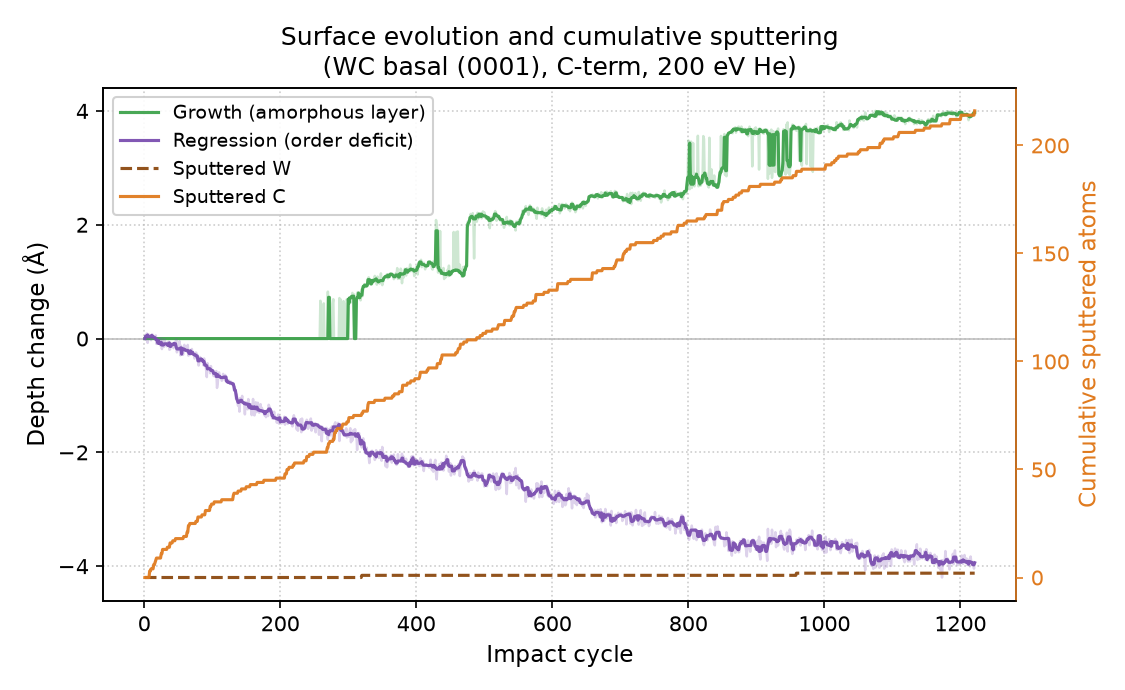

composition_profile.png


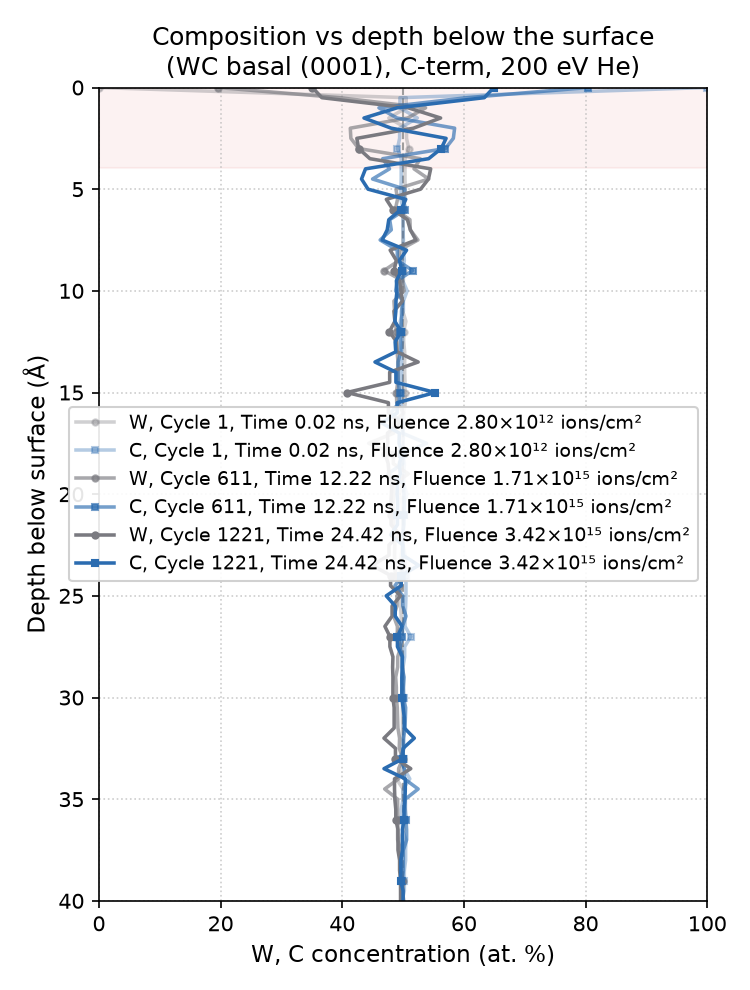

he_profile.png


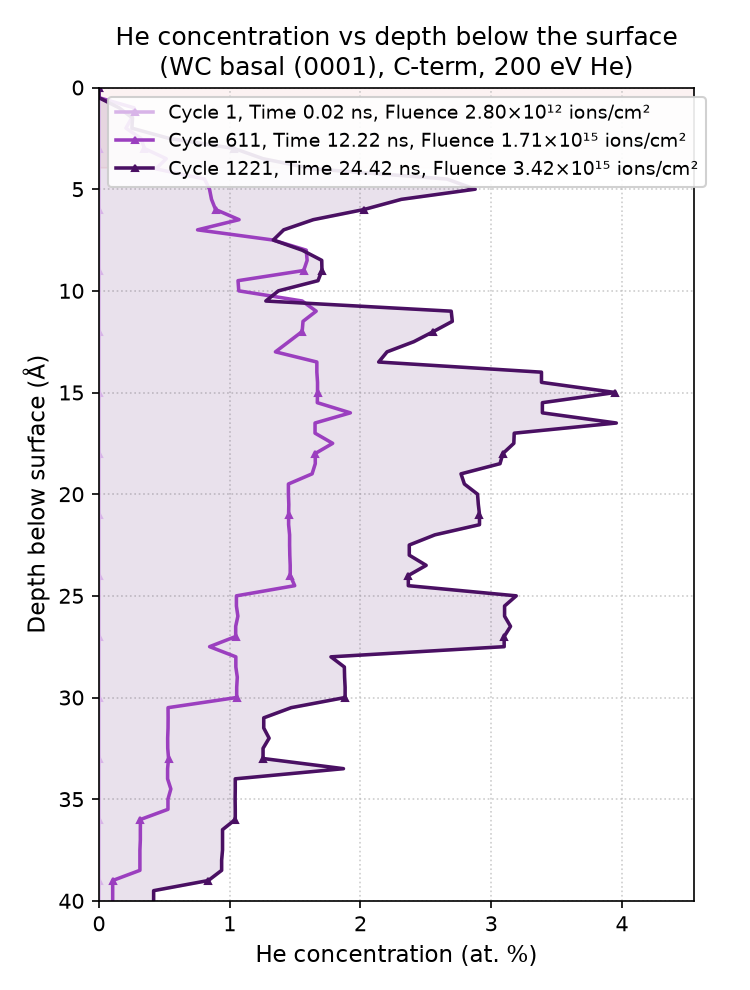

full_iso_final.png


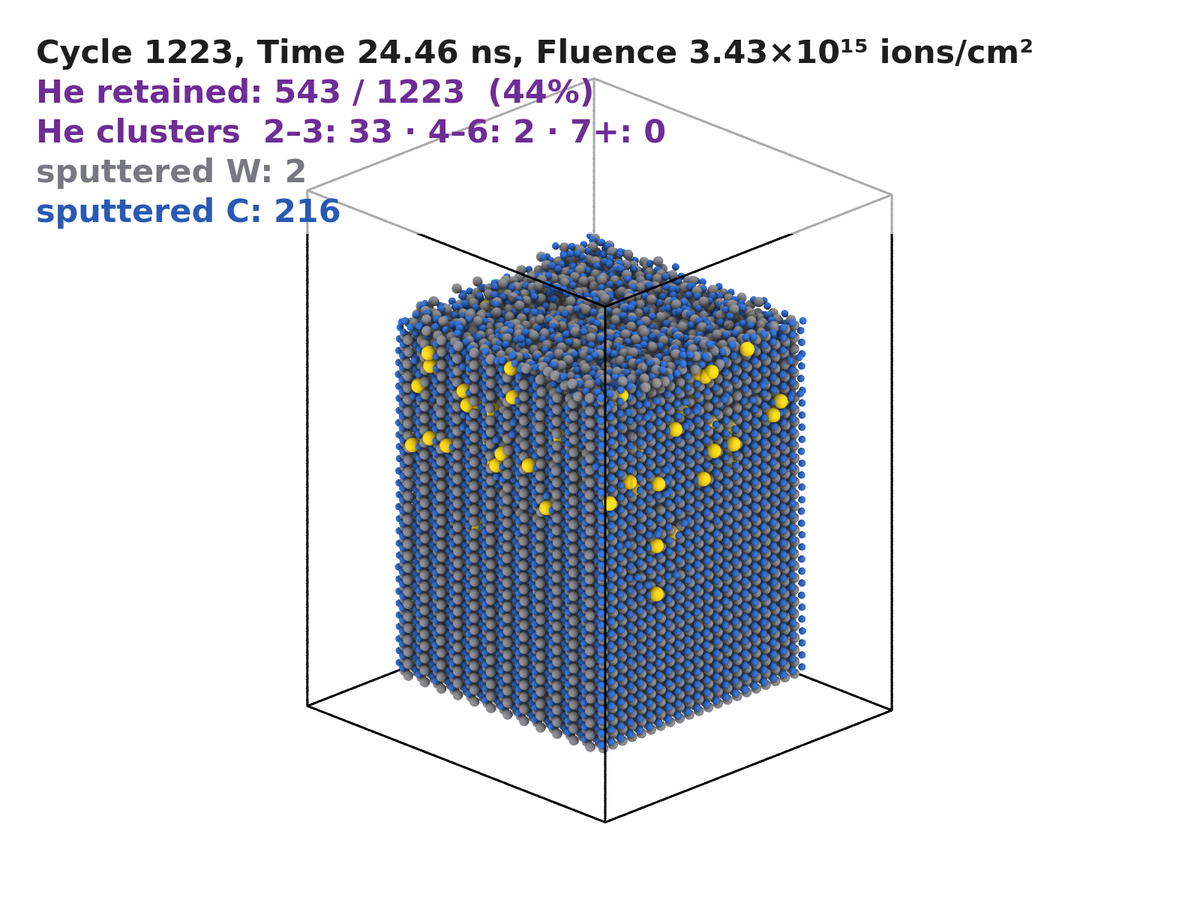

full_side_final.png


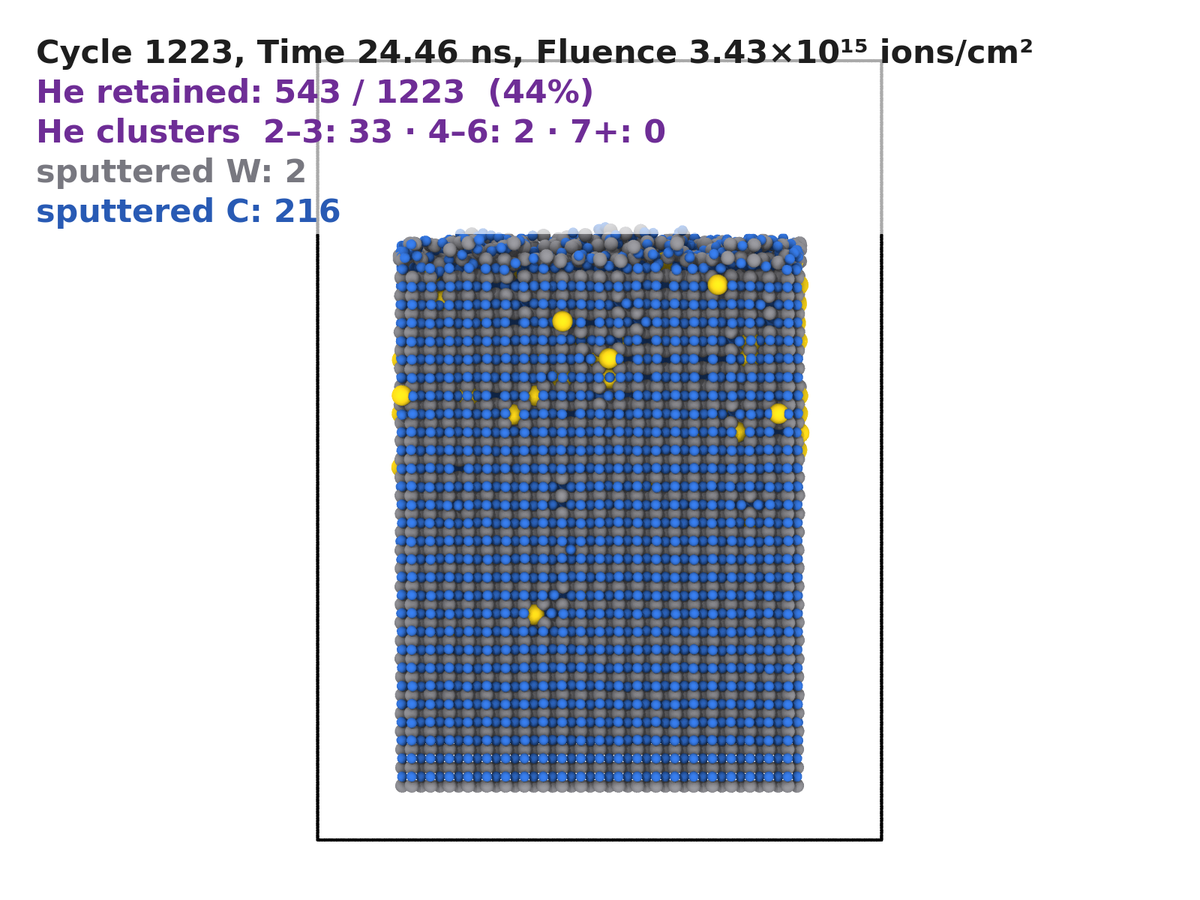

planes_side_final.png


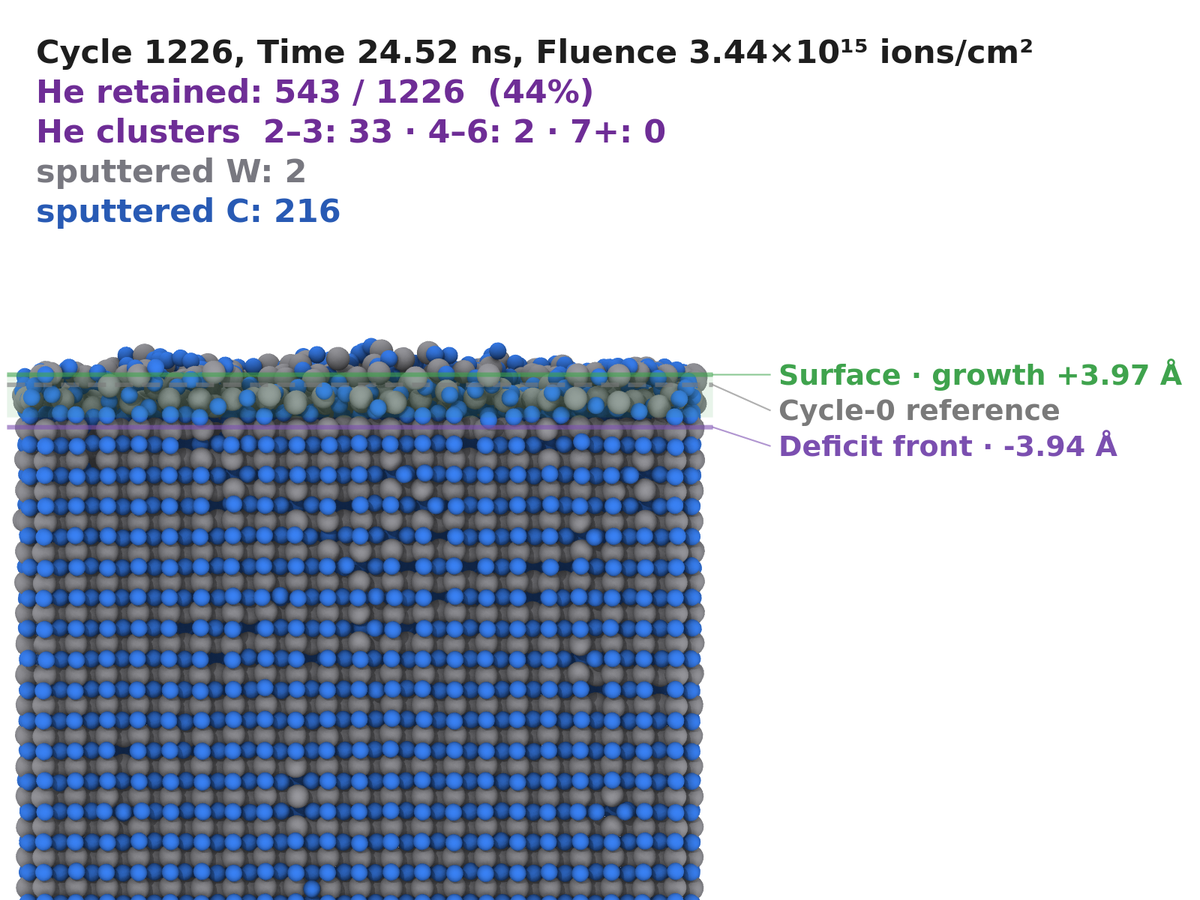

depth_slice.png


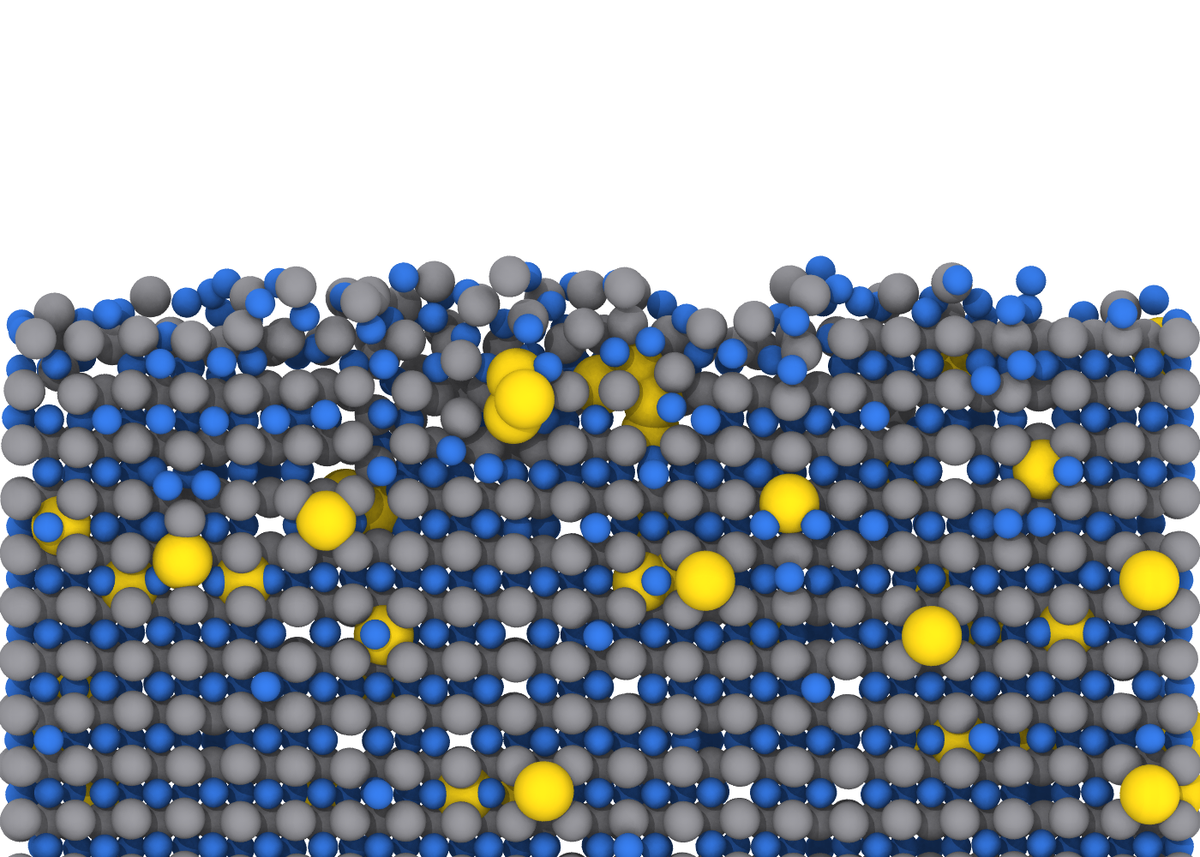

In [3]:
show(NB_RUN, ['erosion_combined.png', 'composition_profile.png', 'he_profile.png', 'full_iso_final.png', 'full_side_final.png', 'planes_side_final.png', 'depth_slice.png', 'full_iso.gif'])